# Initial error-rate estimation

This notebook records the production-style call used for the chromosome 17
error-estimation dataset. The estimator cell is intentionally not executed
as part of repository checks.

## Validation against old version

In [2]:
import dataclasses
import pathlib

import IPython.display as ipython_display
import numpy as np
import pandas as pd
import zarr

from ch4 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()

In [3]:
# zarr_dir = Path(
#    "~/work/tsinfer-anc-eval/data/anc_eval/zarr_vcfs/"
# ).expanduser()
# zarr_prefix = "OutOfAfrica_4J17-chr20-L0-R1e7-n600-s1-rep0"
# ts_path = Path(
#    "~/work/tsinfer-anc-eval/data/anc_eval/simulated/"
#    "OutOfAfrica_4J17-chr20-L0-R1e7-n600-s1-rep0.trees"
# ).expanduser()
zarr_dir = pathlib.Path(
    "~/work/tsinfer-anc-eval/data/error_eval/zarr_vcfs/"
).expanduser()
zarr_prefix = "OutOfAfrica_4J17-chr17-L0-R22.7e6-n3202-s1-rep0"
ts_path = pathlib.Path(
    "~/work/tsinfer-anc-eval/data/error_eval/simulated/OutOfAfrica_4J17-chr17-L0-R22.7e6-n3202-s1-rep0.trees"
).expanduser()
recombination = (
    repository_dir / "data/general/HapMapII_GRCh38/genetic_map_Hg38_chr17.txt"
).expanduser()
window_sizes = np.geomspace(100, 1000000, 100)
config = nb_utils.make_estimation_config(
    window_sizes=window_sizes,
    num_doubletons=10000,
    random_seed=42,
    exclude_high_mismatch_proportion=0.25,
    L_mismatch_trim=window_sizes[-1],
)

In [4]:
error_multipliers = [0, 1, 2, 5, 10]
true_diversity = nb_utils.get_ts_diversity(ts_path)
zero_error_zarr_path = zarr_dir / f"{zarr_prefix}-geno-0.0-phase0.0-mispol0.0.zarr"
true_doubletons_config = dataclasses.replace(
    config, num_doubletons=7500, exclude_high_mismatch_proportion=0
)
true_doubletons = nb_utils.sample_doubletons(
    zero_error_zarr_path, true_doubletons_config
)
true_doubletons_path = repository_dir / "data/ch4/validation/true_doubletons.csv"
true_doubletons_path.parent.mkdir(parents=True, exist_ok=True)
nb_utils.write_doubletons_csv(true_doubletons, true_doubletons_path)
ascertained_estimates = {}
true_doubleton_estimates = {}
rows = []
for multiplier in error_multipliers:
    zarr_path = (
        zarr_dir / f"{zarr_prefix}-geno-{multiplier:.1f}-phase0.0-mispol0.0.zarr"
    )
    ascertained_estimate = nb_utils.estimate_error_rate(
        zarr_path, recombination=recombination, config=config
    )
    true_doubleton_estimate = nb_utils.estimate_error_rate(
        zarr_path,
        recombination=recombination,
        config=true_doubletons_config,
        fixed_doubletons_path=true_doubletons_path,
    )
    ascertained_estimates[multiplier] = ascertained_estimate
    true_doubleton_estimates[multiplier] = true_doubleton_estimate
    rows.append(
        {
            "error_multiplier": multiplier,
            "diversity": ascertained_estimate.diversity.global_pi_per_bp,
            "epsilon": ascertained_estimate.fit.epsilon,
            "mu": ascertained_estimate.fit.mu,
            "pi": ascertained_estimate.fit.pi,
            "sigma_sq": ascertained_estimate.fit.sigma_sq,
            "true_doubleton_epsilon": true_doubleton_estimate.fit.epsilon,
            "true_doubleton_mu": true_doubleton_estimate.fit.mu,
            "true_doubleton_pi": true_doubleton_estimate.fit.pi,
            "true_doubleton_sigma_sq": true_doubleton_estimate.fit.sigma_sq,
            "true_error": nb_utils.get_true_error_rate(zarr_path),
            "true_diversity": true_diversity,
        }
    )
fit_df = pd.DataFrame(rows)
fit_df

,error_multiplier,diversity,epsilon,mu,pi,sigma_sq,true_doubleton_epsilon,true_doubleton_mu,true_doubleton_pi,true_doubleton_sigma_sq,true_error,true_diversity
0,0,0.000732,6.693414e-08,11.179786,0.000732,124.988692,0.000003,34.235594,0.000732,2589.292812,0.000000,0.000732
1,1,0.000730,1.974675e-05,21.206161,0.000730,873.715826,0.000014,33.646161,0.000730,2636.119403,0.000011,0.000732
2,2,0.000729,5.876596e-05,24.314807,0.000729,1560.629187,0.000023,33.168720,0.000729,2739.113788,0.000022,0.000732
3,5,0.000728,1.795576e-04,31.218362,0.000728,10180.213638,0.000047,32.525859,0.000728,3163.985424,0.000050,0.000732
4,10,0.000730,2.924136e-04,15.922965,0.000730,10898.384609,0.000081,29.480736,0.000730,3080.035301,0.000093,0.000732


In [5]:
fit_df.to_csv("data/ch4/validation/dphil-analysis-results.csv", index=None)

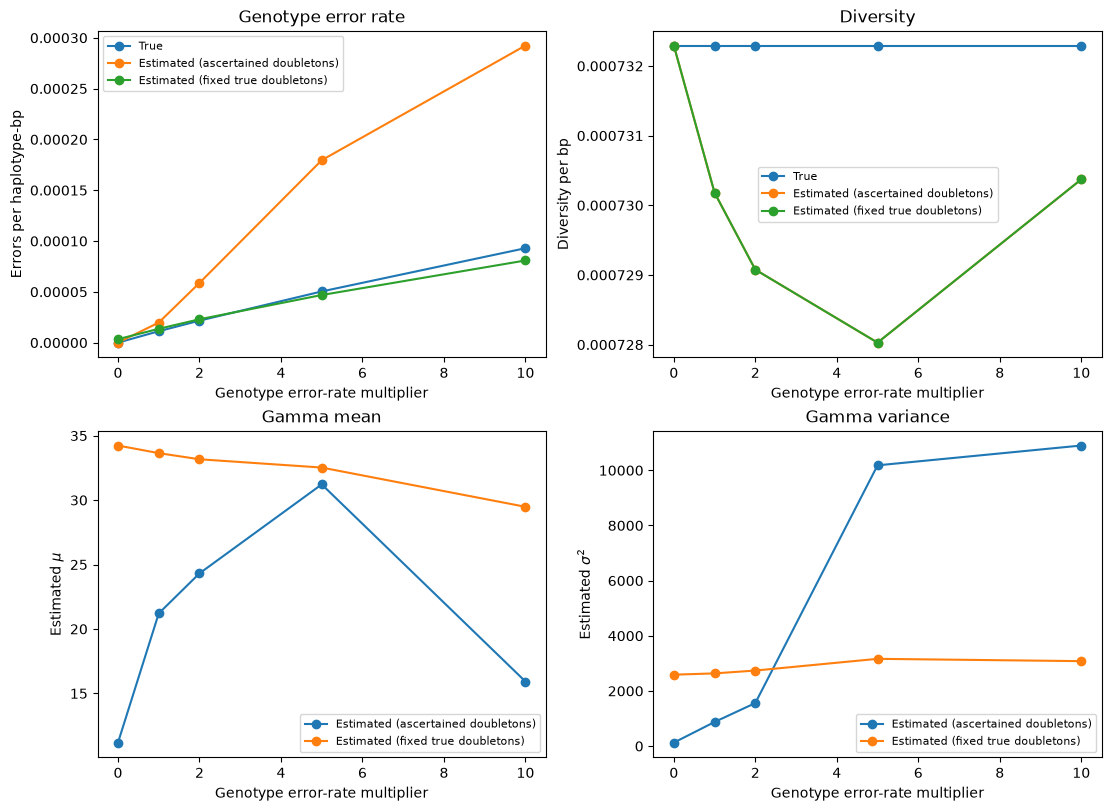

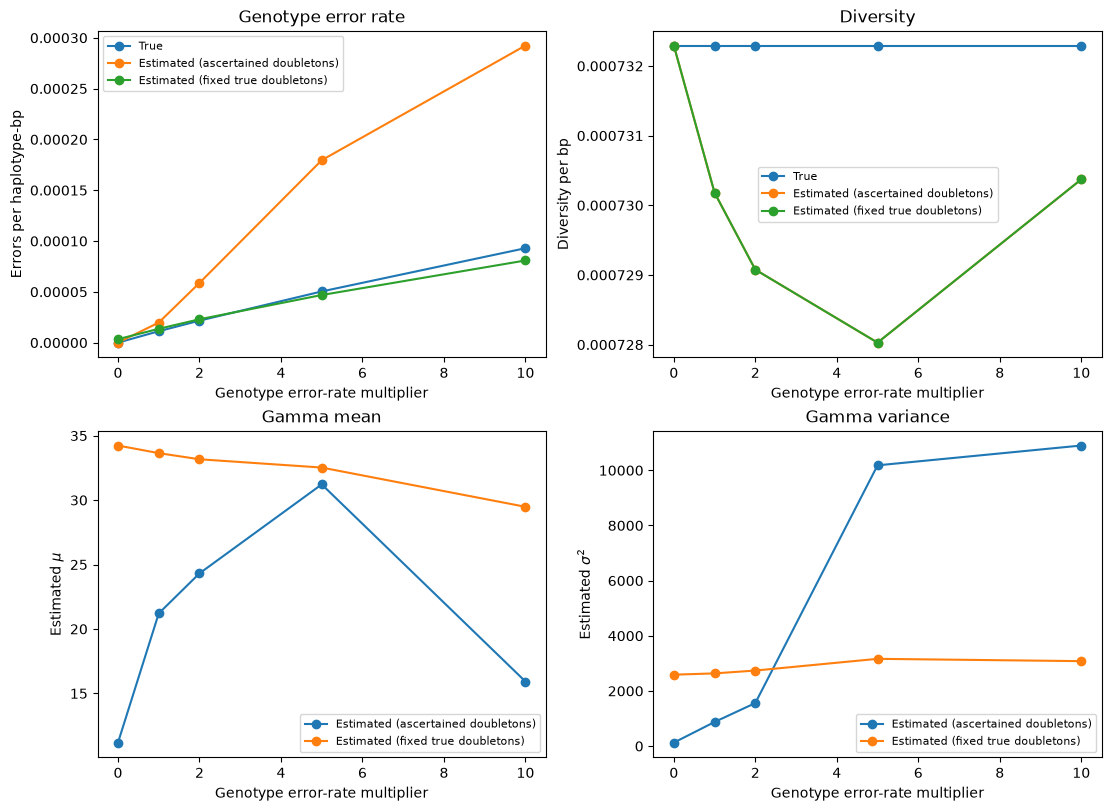

In [6]:
nb_plot.plot_error_estimates(
    fit_df, "Estimated (ascertained doubletons)", figsize=(11, 8)
)

In [7]:
## Doubleton ascertainment testing

In [8]:
cutoff_proportions = [0.1, 0.25, 0.5, 0.75]
L_mismatch_trim_values = [config.window_sizes[0], config.window_sizes[-1]]
classification_records = []
true_doubleton_masks = {}
for multiplier, estimate in ascertained_estimates.items():
    true_doubleton_mask = nb_utils.get_true_doubleton_mask(
        estimate.doubletons, zero_error_zarr_path
    )
    true_doubleton_masks[multiplier] = true_doubleton_mask
    records = nb_utils.evaluate_mismatch_cutoffs(
        estimate.mismatches,
        true_doubleton_mask,
        cutoff_proportions=cutoff_proportions,
        L_mismatch_trim_values=L_mismatch_trim_values,
    )
    for record in records:
        record["error_multiplier"] = multiplier
    classification_records.extend(records)
classification_df = pd.DataFrame(classification_records)

In [9]:
classification_df

,L_mismatch_trim,cutoff_proportion,num_doubletons,num_actual_positive,num_actual_negative,num_retained,tp,fp,fn,tn,prevalence,tpr,fpr,tnr,precision,npv,accuracy,error_multiplier
0,100.0,0.10,10000,10000,0,9000,9000,0,1000,0,1.0000,0.900000,NaN,NaN,1.000000,0.000000,0.9000,0
1,100.0,0.25,10000,10000,0,7500,7500,0,2500,0,1.0000,0.750000,NaN,NaN,1.000000,0.000000,0.7500,0
2,100.0,0.50,10000,10000,0,5000,5000,0,5000,0,1.0000,0.500000,NaN,NaN,1.000000,0.000000,0.5000,0
3,100.0,0.75,10000,10000,0,2500,2500,0,7500,0,1.0000,0.250000,NaN,NaN,1.000000,0.000000,0.2500,0
4,1000000.0,0.10,10000,10000,0,9000,9000,0,1000,0,1.0000,0.900000,NaN,NaN,1.000000,0.000000,0.9000,0
5,1000000.0,0.25,10000,10000,0,7500,7500,0,2500,0,1.0000,0.750000,NaN,NaN,1.000000,0.000000,0.7500,0
6,1000000.0,0.50,10000,10000,0,5000,5000,0,5000,0,1.0000,0.500000,NaN,NaN,1.000000,0.000000,0.5000,0
7,1000000.0,0.75,10000,10000,0,2500,2500,0,7500,0,1.0000,0.250000,NaN,NaN,1.000000,0.000000,0.2500,0
8,100.0,0.10,10000,6662,3338,9000,6145,2855,517,483,0.6662,0.922396,0.855303,0.144697,0.682778,0.483000,0.6628,1
9,100.0,0.25,10000,6662,3338,7500,5138,2362,1524,976,0.6662,0.771240,0.707609,0.292391,0.685067,0.390400,0.6114,1


### Mismatch rate as a doubleton classifier

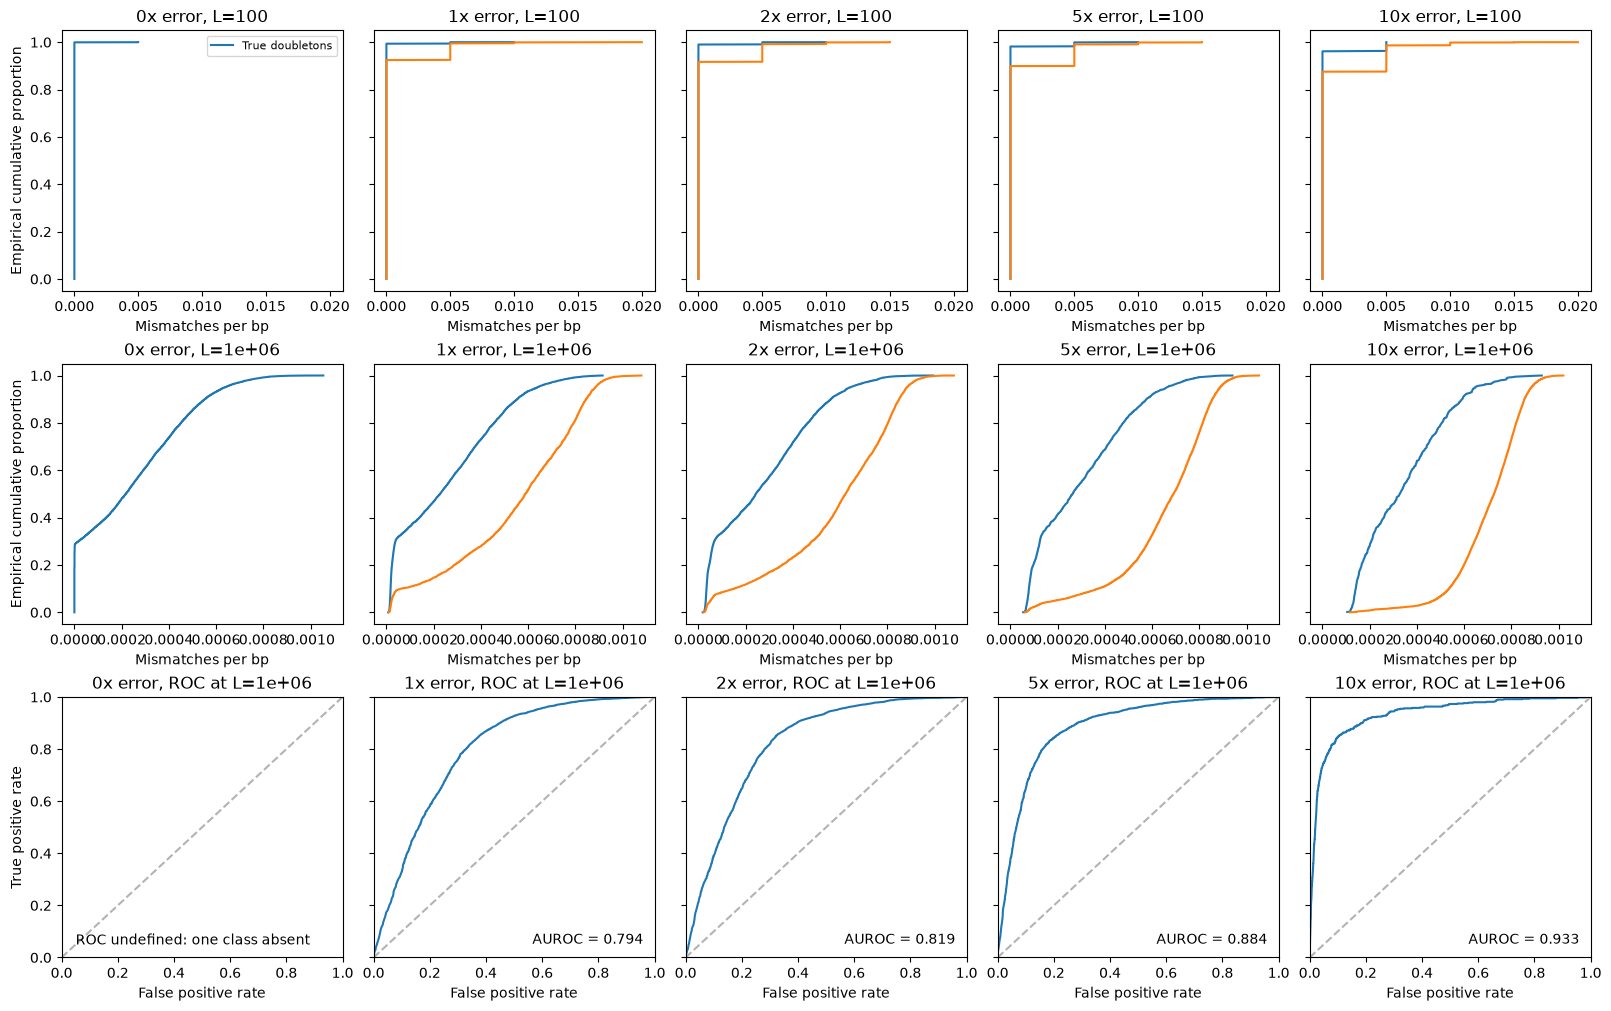

In [10]:
fig = nb_plot.plot_mismatch_rate_as_a_doubleton_classifier(
    L_mismatch_trim_values=L_mismatch_trim_values,
    ascertained_estimates=ascertained_estimates,
    config=config,
    error_multipliers=error_multipliers,
    true_doubleton_masks=true_doubleton_masks,
    figsize=(16, 10),
    linestyle="--",
    color="0.7",
    fontsize=8,
)

Text(0.5, 1.0, 'True-doubleton prevalence')

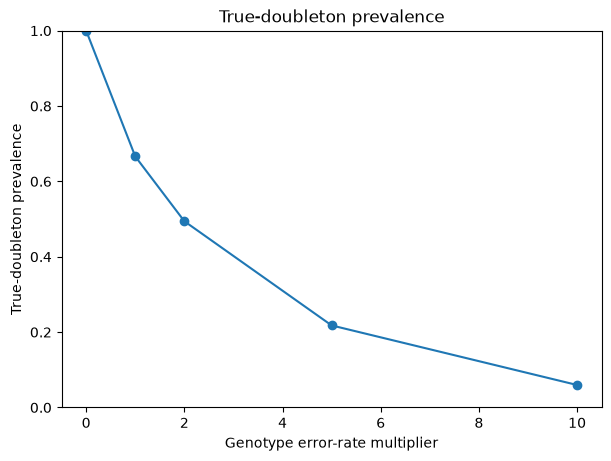

In [11]:
prevalence_df = (
    classification_df[["error_multiplier", "prevalence"]]
    .drop_duplicates()
    .sort_values("error_multiplier")
)
fig = nb_plot.plot_mismatch_rate_as_a_doubleton_classifier_2(
    prevalence_df=prevalence_df, figsize=(6, 4.5), marker="o"
)

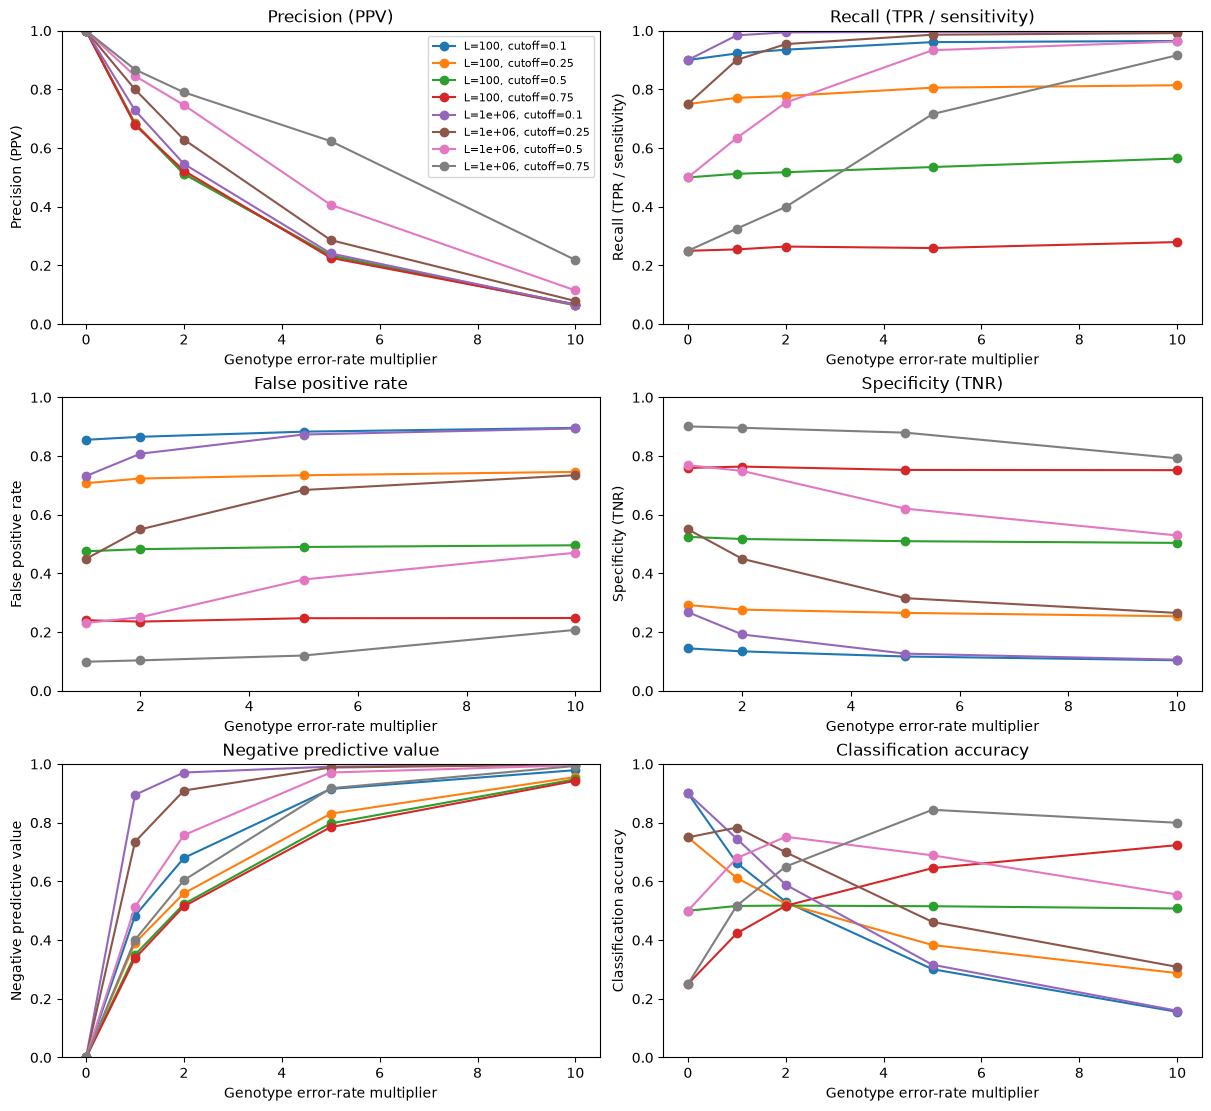

In [12]:
metric_specs = [
    ("precision", "Precision (PPV)"),
    ("tpr", "Recall (TPR / sensitivity)"),
    ("fpr", "False positive rate"),
    ("tnr", "Specificity (TNR)"),
    ("npv", "Negative predictive value"),
    ("accuracy", "Classification accuracy"),
]
fig = nb_plot.plot_mismatch_rate_as_a_doubleton_classifier_3(
    L_mismatch_trim_values=L_mismatch_trim_values,
    classification_df=classification_df,
    cutoff_proportions=cutoff_proportions,
    metric_specs=metric_specs,
    figsize=(12, 11),
    marker="o",
    fontsize=8,
)

### Cumulative counts by doubleton type

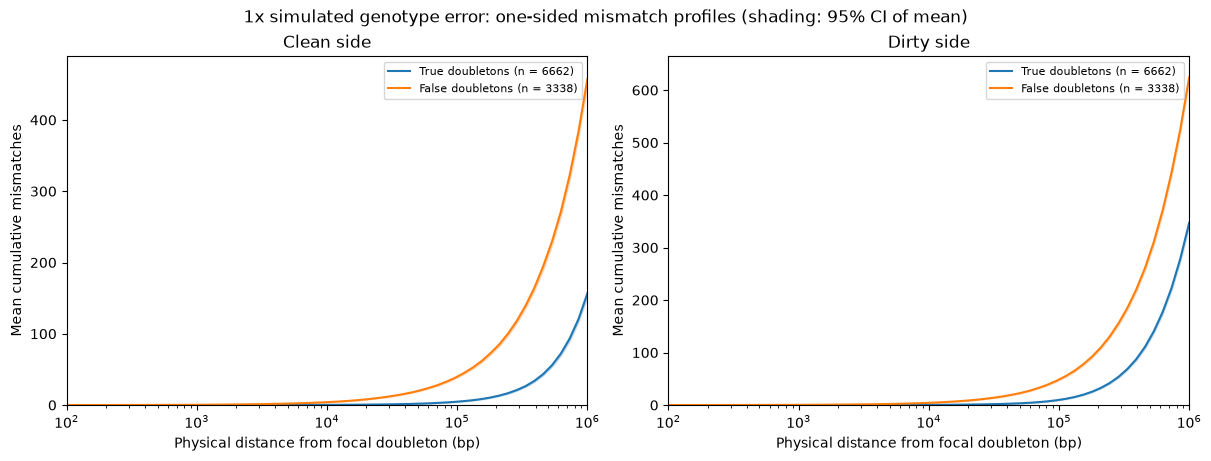

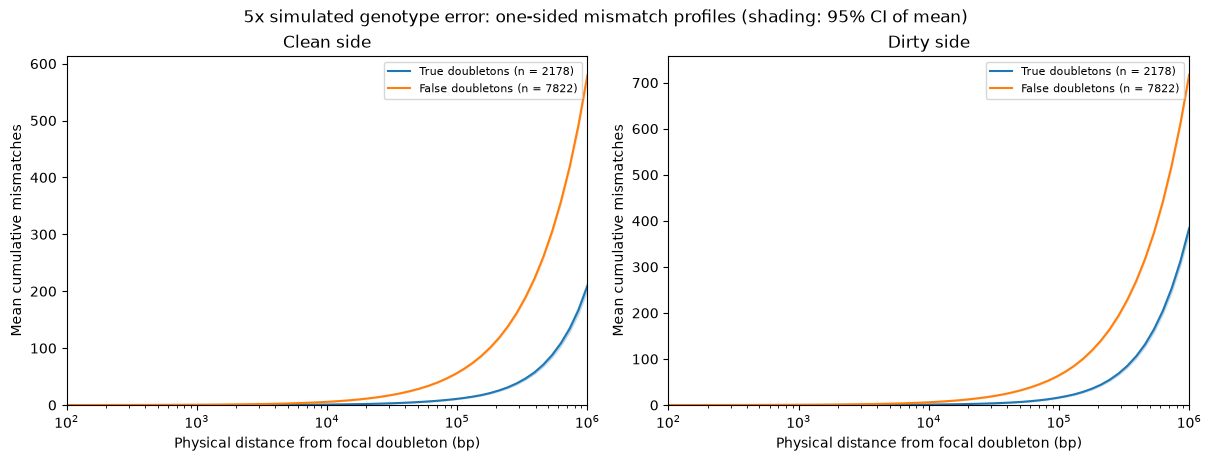

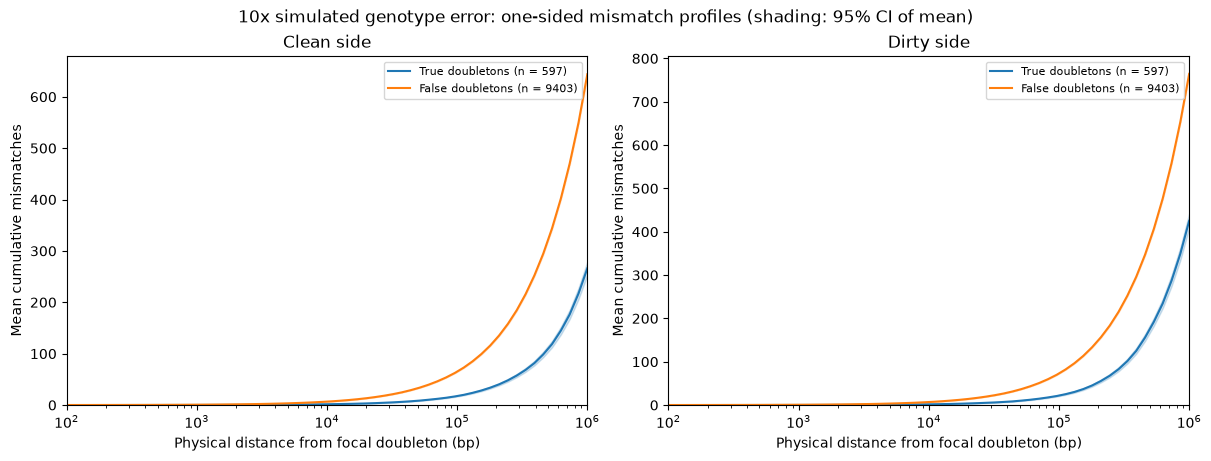

In [15]:
profile_distances = np.geomspace(100, config.window_sizes[-1], 60)
cumulative_profiles = {}
for multiplier in [1, 5, 10]:
    profiles = nb_utils.cumulative_mismatch_profiles(
        ascertained_estimates[multiplier],
        zero_error_zarr_path,
        distances=profile_distances,
    )
    cumulative_profiles[multiplier] = profiles
    profile_fig = nb_plot.plot_cumulative_mismatch_profiles(
        profiles,
        f"{multiplier}x simulated genotype error: one-sided mismatch profiles",
        figsize=(12, 4.5),
    )
    ipython_display.display(profile_fig)
    nb_plot.close_figure(profile_fig)

### Per-doubleton mismatch summaries

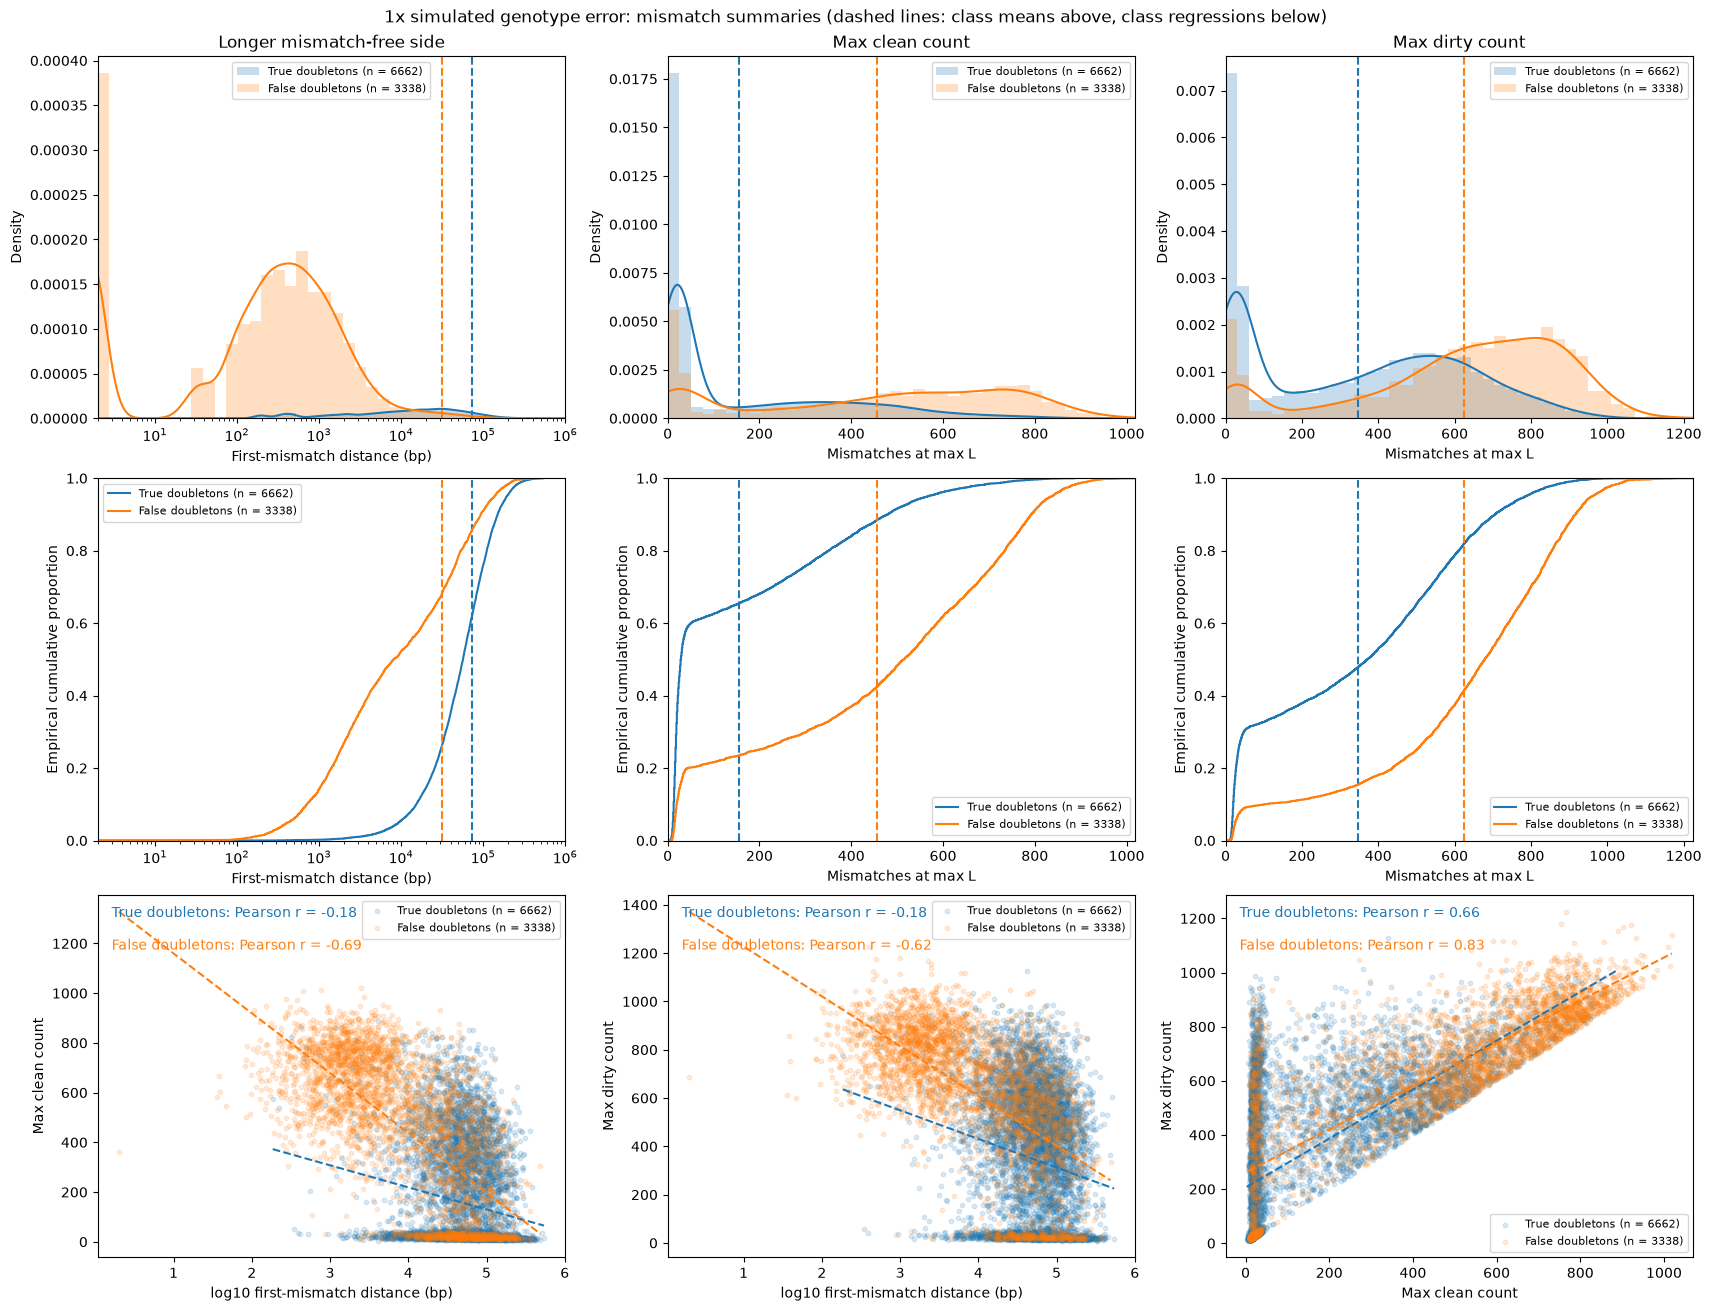

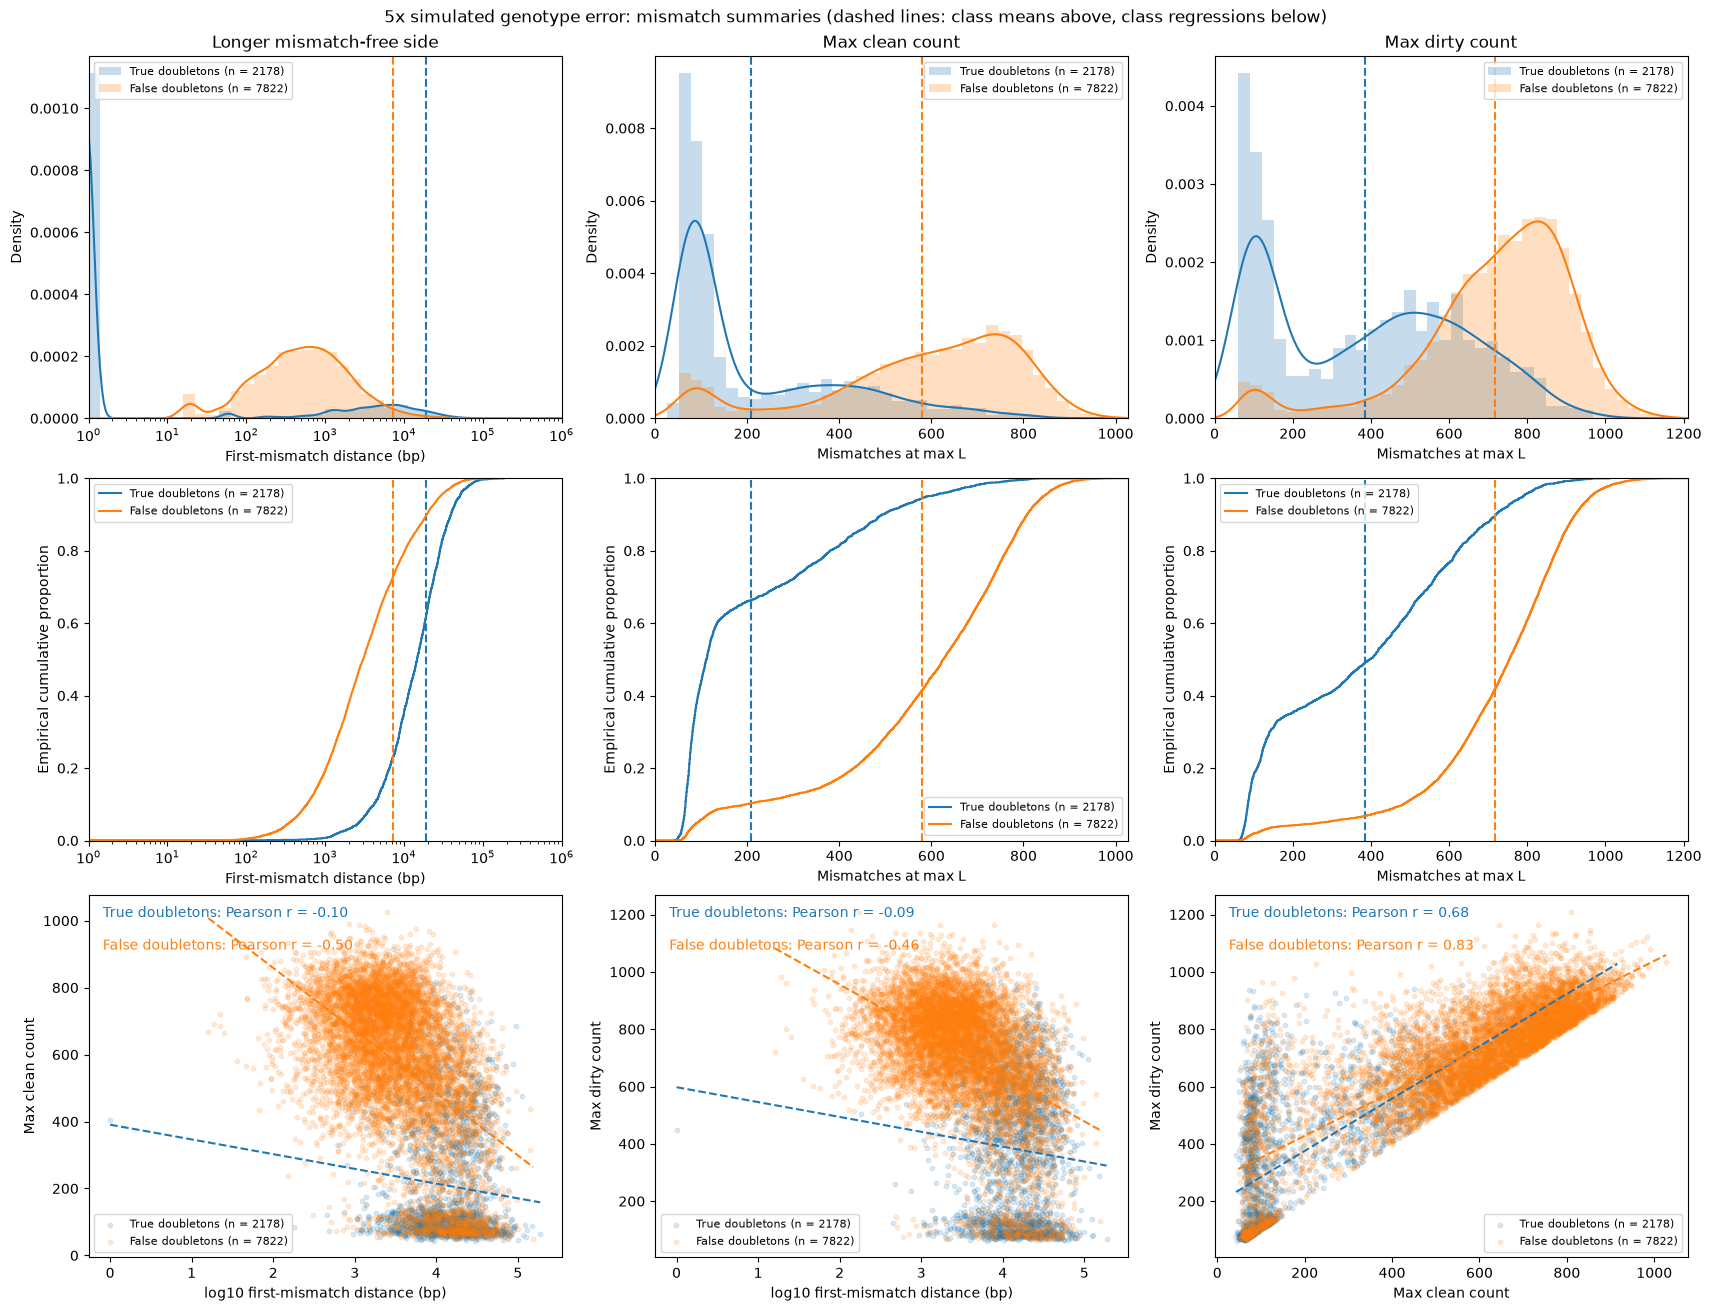

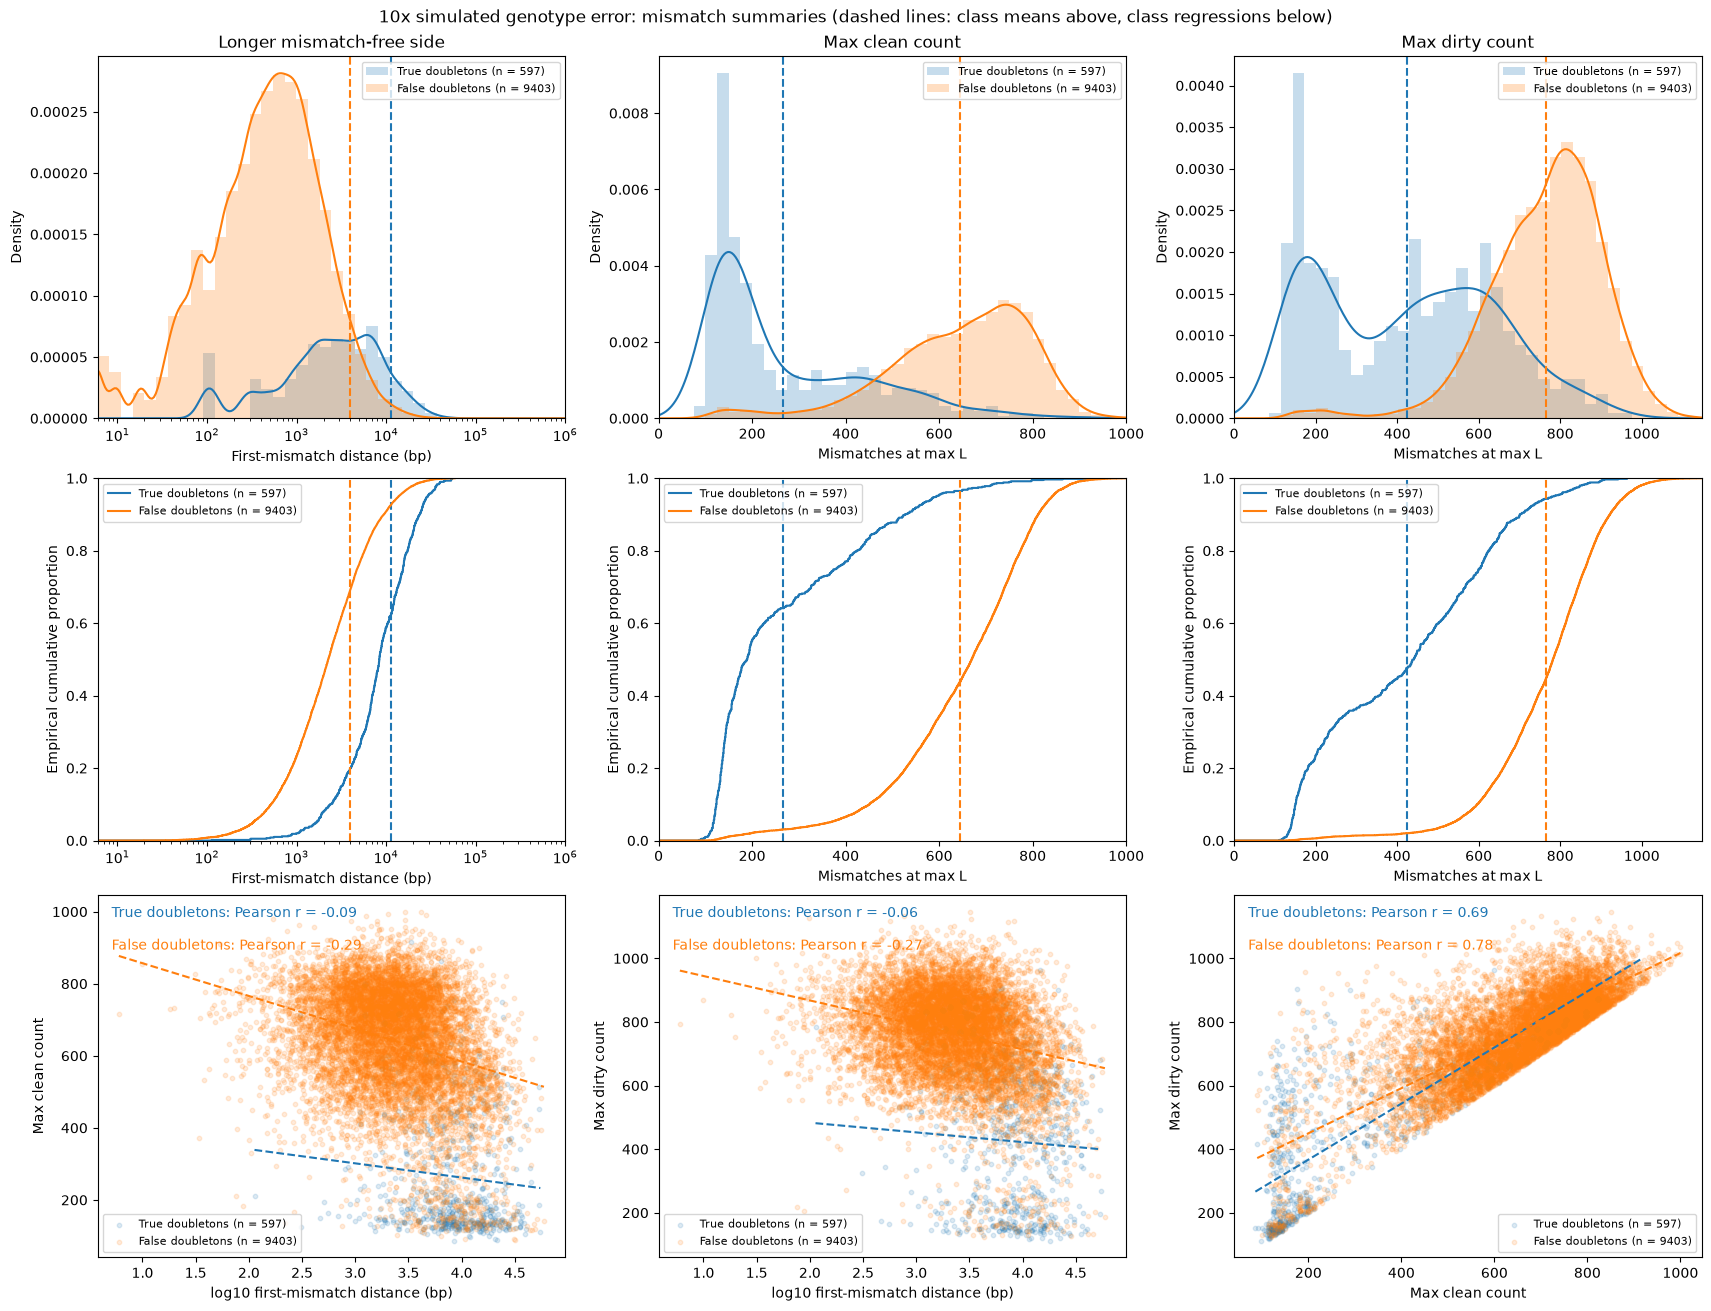

In [16]:
for multiplier in [1, 5, 10]:
    summary_fig = nb_plot.plot_doubleton_mismatch_summaries(
        cumulative_profiles[multiplier],
        f"{multiplier}x simulated genotype error: mismatch summaries",
        figsize=(17, 13),
    )
    ipython_display.display(summary_fig)
    nb_plot.close_figure(summary_fig)

## Fitting models to doubleton data

In [17]:
for multiplier in [0, 2]:
    cumulative_profiles[multiplier] = nb_utils.cumulative_mismatch_profiles(
        ascertained_estimates[multiplier],
        zero_error_zarr_path,
        distances=profile_distances,
    )
classifier_tiers = ["tier_0", "tier_1", "tier_1b", "tier_2", "tier_3"]
classifier_labels = {
    "tier_0": "Fixed 25% mismatch trim",
    "tier_1": "First-mismatch threshold",
    "tier_1b": "Clean-count threshold",
    "tier_2": "Two-feature logistic",
    "tier_3": "Logistic with interaction",
}
training_multipliers = [1, 5, 10]
classifier_rows = []
classifier_curves = {}
held_out_models = {}
for held_out_multiplier in training_multipliers:
    training_profiles = [
        cumulative_profiles[multiplier]
        for multiplier in training_multipliers
        if multiplier != held_out_multiplier
    ]
    test_profiles = cumulative_profiles[held_out_multiplier]
    estimate = ascertained_estimates[held_out_multiplier]
    true_epsilon = fit_df.loc[
        fit_df["error_multiplier"] == held_out_multiplier, "true_error"
    ].iloc[0]
    for tier in classifier_tiers:
        if tier == "tier_0":
            model = nb_utils.make_doubleton_classifier(tier=tier, threshold=None)
        else:
            model = nb_utils.fit_doubleton_classifier(tier, training_profiles)
        held_out_models[held_out_multiplier, tier] = model
        scores, retained = nb_utils.classify_doubletons(
            model, test_profiles, estimate.mismatches
        )
        metrics = nb_utils.classifier_metrics(
            scores, test_profiles.is_true_doubleton, retained
        )
        fitted = nb_utils.fit_error_rate_with_selected_doubletons(estimate, retained)
        metrics.update(
            {
                "tier": tier,
                "test_multiplier": held_out_multiplier,
                "fitted_epsilon": fitted.epsilon,
                "epsilon_relative_error": abs(fitted.epsilon - true_epsilon)
                / true_epsilon,
                "fitted_mu": fitted.mu,
                "fitted_sigma_sq": fitted.sigma_sq,
            }
        )
        classifier_rows.append(metrics)
        classifier_curves[held_out_multiplier, tier] = nb_utils.classifier_curves(
            scores, test_profiles.is_true_doubleton
        )
classifier_cv_df = pd.DataFrame(classifier_rows)
classifier_cv_summary = classifier_cv_df.groupby("tier", sort=False)[
    [
        "auroc",
        "average_precision",
        "tpr",
        "fpr",
        "precision",
        "fraction_retained",
        "epsilon_relative_error",
    ]
].mean()
ipython_display.display(classifier_cv_df)
ipython_display.display(classifier_cv_summary)

,auroc,average_precision,tpr,fpr,precision,fraction_retained,tier,test_multiplier,fitted_epsilon,epsilon_relative_error,fitted_mu,fitted_sigma_sq
0,0.793572,0.851607,0.900480,0.449670,0.799867,0.7500,tier_0,1,0.000020,0.755848,21.206161,8.737158e+02
1,0.780634,0.830052,0.992645,0.711504,0.735759,0.8988,tier_1,1,0.000030,1.700725,76.862150,3.330104e+04
2,0.792508,0.849010,0.960222,0.608748,0.758928,0.8429,tier_1b,1,0.000034,2.049637,26.017510,1.584619e+03
3,0.805579,0.849398,0.981237,0.553625,0.779606,0.8385,tier_2,1,0.000021,0.823675,39.109712,4.898714e+03
4,0.803394,0.842343,0.988442,0.548532,0.782438,0.8416,tier_3,1,0.000017,0.553203,44.301740,6.555405e+03
5,0.883775,0.639532,0.986226,0.684224,0.286400,0.7500,tier_0,5,0.000180,2.563644,31.218362,1.018021e+04
6,0.811714,0.474442,0.819100,0.311429,0.422749,0.4220,tier_1,5,0.000030,0.397383,550.890873,1.964692e+06
7,0.882421,0.627789,0.940312,0.398108,0.396745,0.5162,tier_1b,5,0.000121,1.397102,24.205279,3.401484e+03
8,0.889582,0.604420,0.874197,0.210816,0.535885,0.3553,tier_2,5,0.000039,0.221994,86.053055,4.964019e+04
9,0.895227,0.617292,0.876492,0.201483,0.547776,0.3485,tier_3,5,0.000042,0.161930,60.654052,2.127798e+04


,auroc,average_precision,tpr,fpr,precision,fraction_retained,epsilon_relative_error
tier,,,,,,,
tier_0,0.870232,0.685096,0.959444,0.622851,0.388400,0.750000,1.821893
tier_1,0.803279,0.508107,0.848471,0.417620,0.442323,0.526933,0.850804
tier_1b,0.868643,0.674194,0.945628,0.431120,0.442505,0.561467,1.595880
tier_2,0.877121,0.648779,0.883134,0.283492,0.561646,0.440700,0.497985
tier_3,0.879990,0.658158,0.885185,0.275706,0.574845,0.436600,0.362545


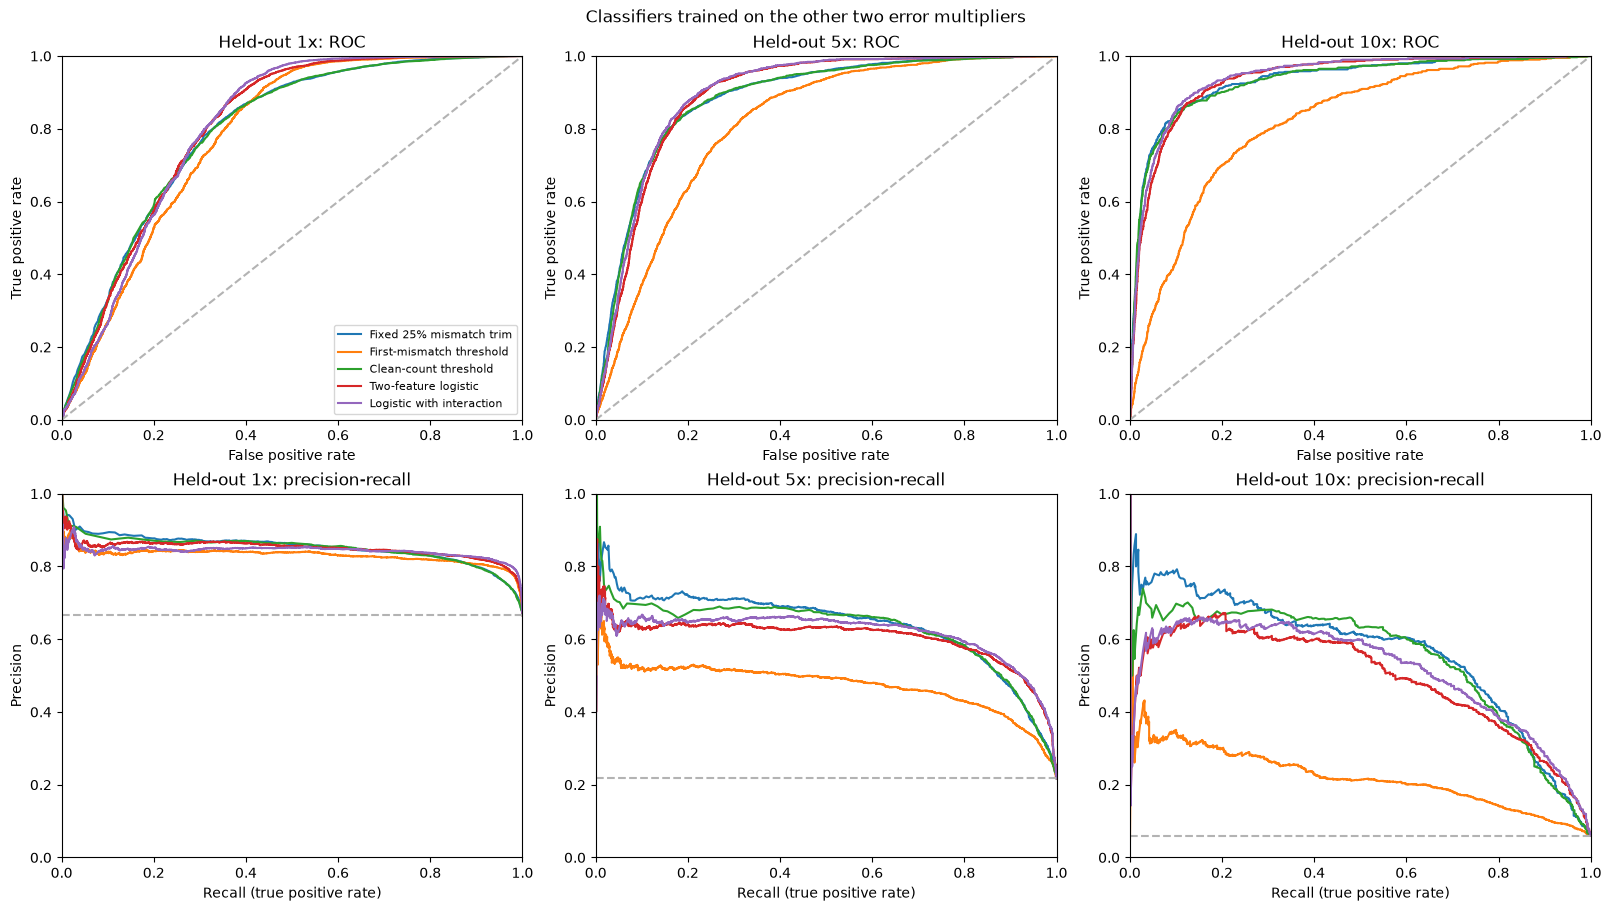

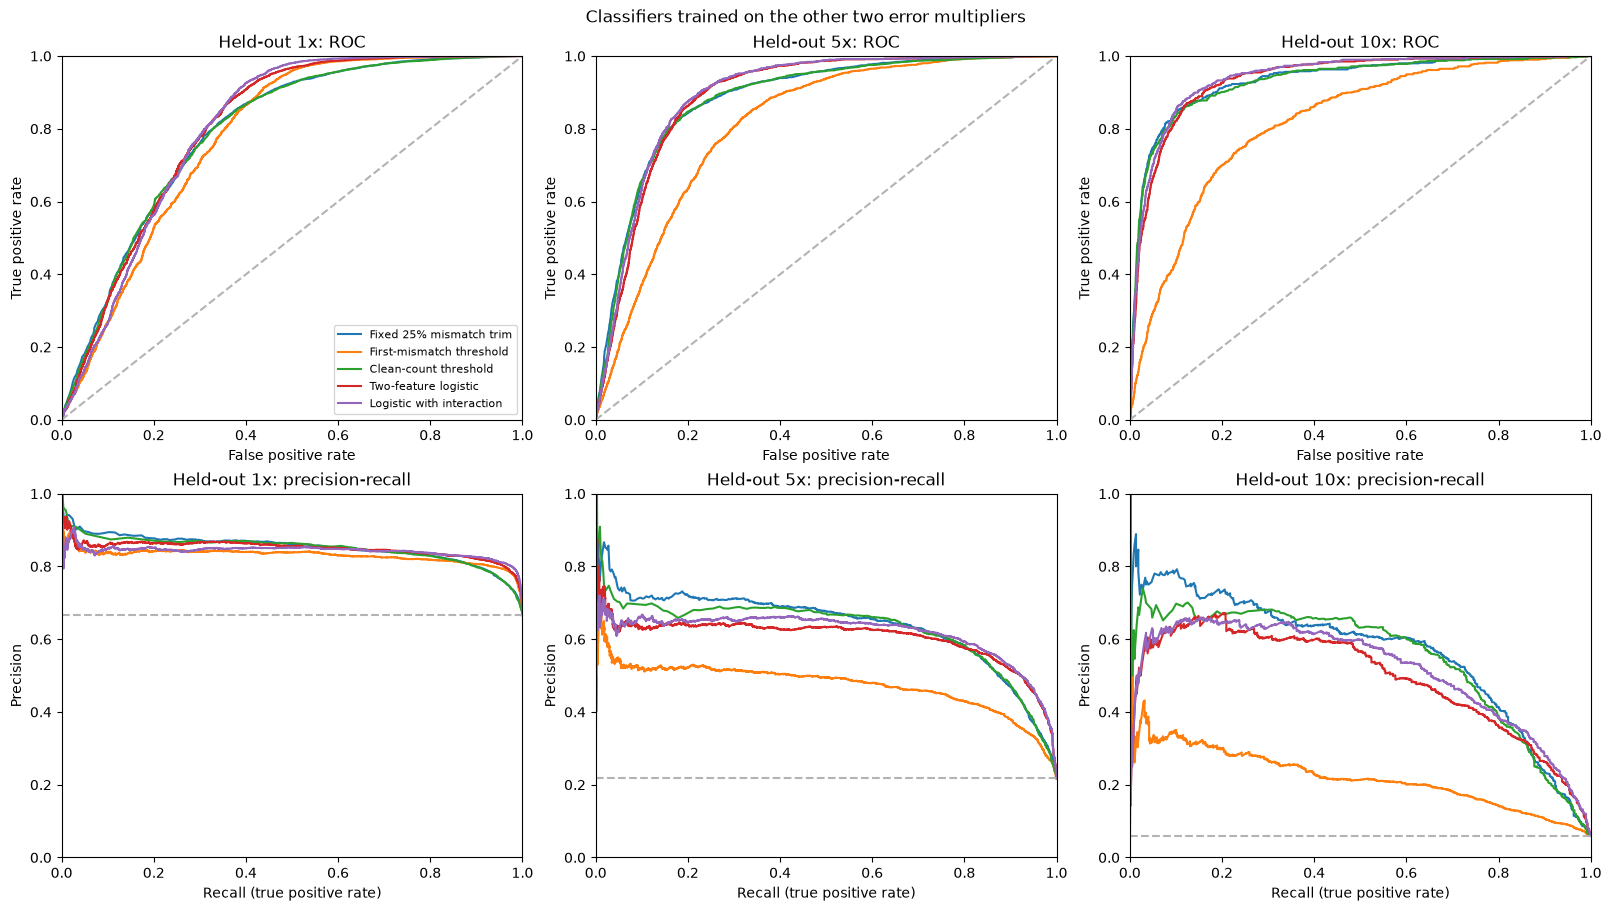

In [18]:
fig = nb_plot.plot_fitting_models_to_doubleton_data(
    classifier_curves=classifier_curves,
    classifier_labels=classifier_labels,
    classifier_tiers=classifier_tiers,
    cumulative_profiles=cumulative_profiles,
    training_multipliers=training_multipliers,
    figsize=(16, 9),
    color="0.7",
    linestyle="--",
    fontsize=8,
)
fig

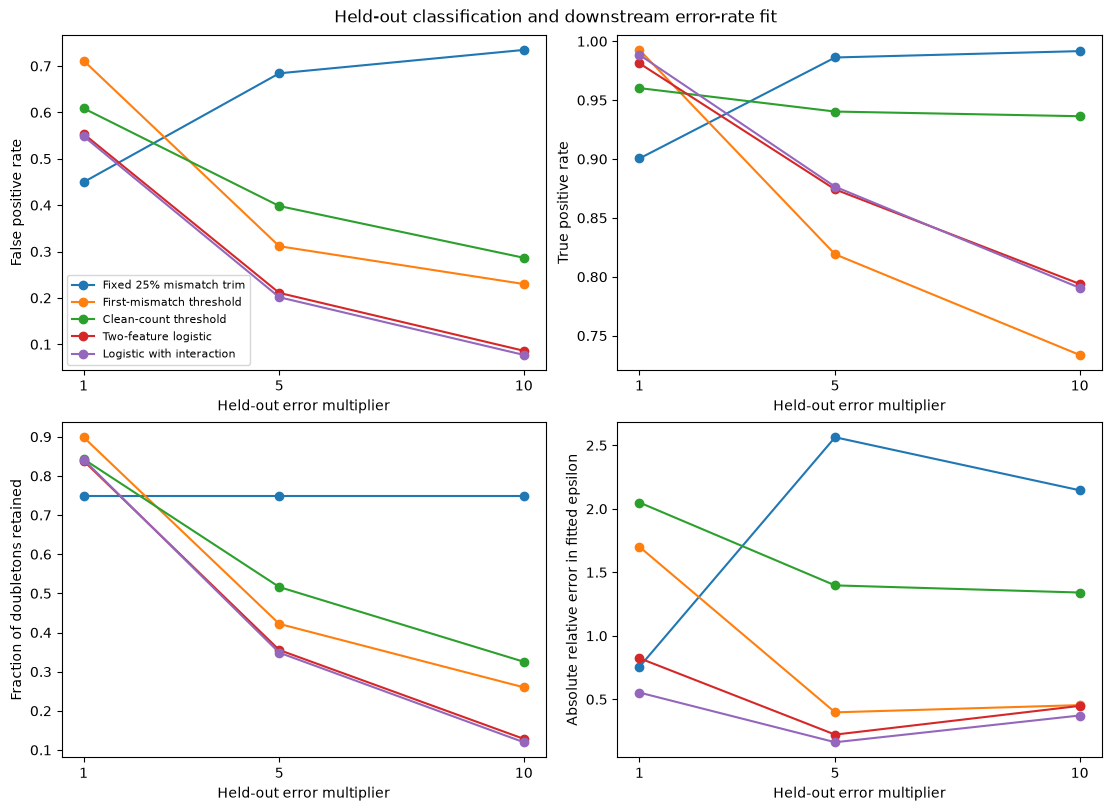

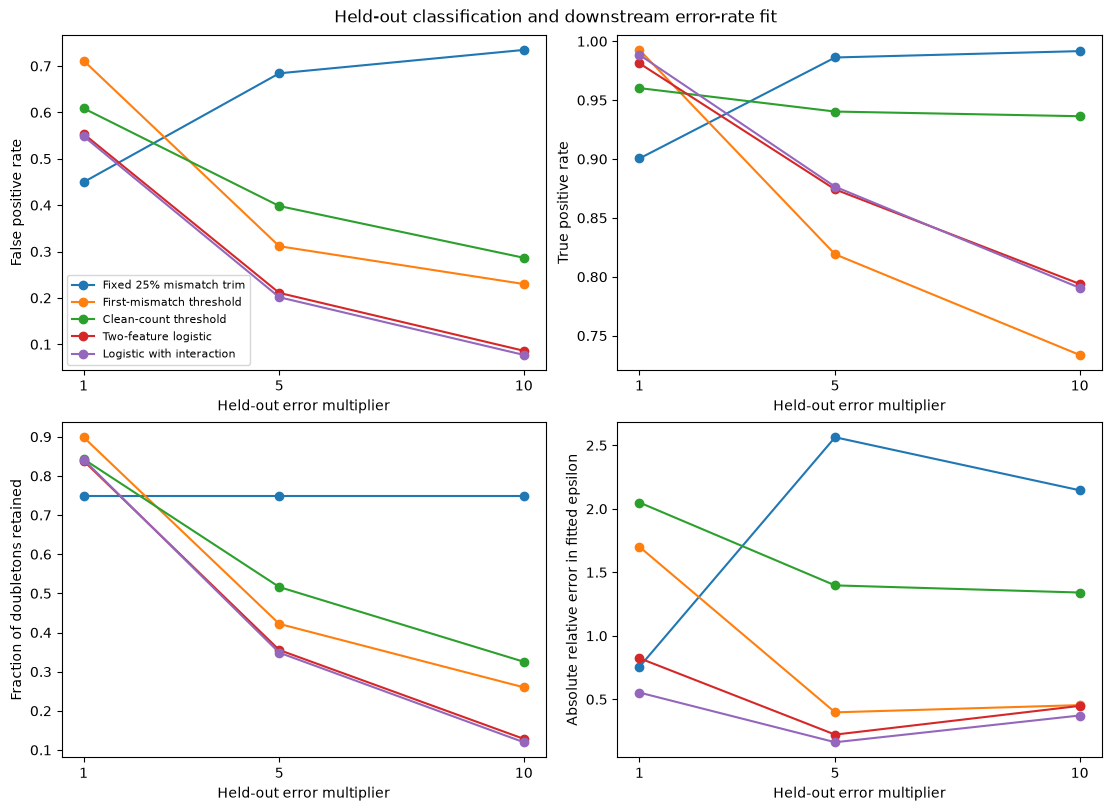

In [19]:
fig = nb_plot.plot_fitting_models_to_doubleton_data_2(
    classifier_cv_df=classifier_cv_df,
    classifier_labels=classifier_labels,
    classifier_tiers=classifier_tiers,
    training_multipliers=training_multipliers,
    figsize=(11, 8),
    marker="o",
    fontsize=8,
)
fig

### Interpolation at 2x and fitted decision surfaces

,auroc,average_precision,tpr,fpr,precision,fraction_retained,tier,fitted_epsilon,epsilon_relative_error
0,0.818887,0.766993,0.954279,0.550326,0.628933,0.7500,tier_0,0.000059,1.714579
1,0.787806,0.719433,0.967429,0.538462,0.637175,0.7505,tier_1,0.000027,0.259094
2,0.815105,0.758098,0.951851,0.537868,0.633670,0.7425,tier_1b,0.000057,1.655667
3,0.827606,0.757028,0.953874,0.410125,0.694506,0.6789,tier_2,0.000023,0.041317
4,0.830219,0.759261,0.956100,0.401028,0.699733,0.6754,tier_3,0.000022,0.001234


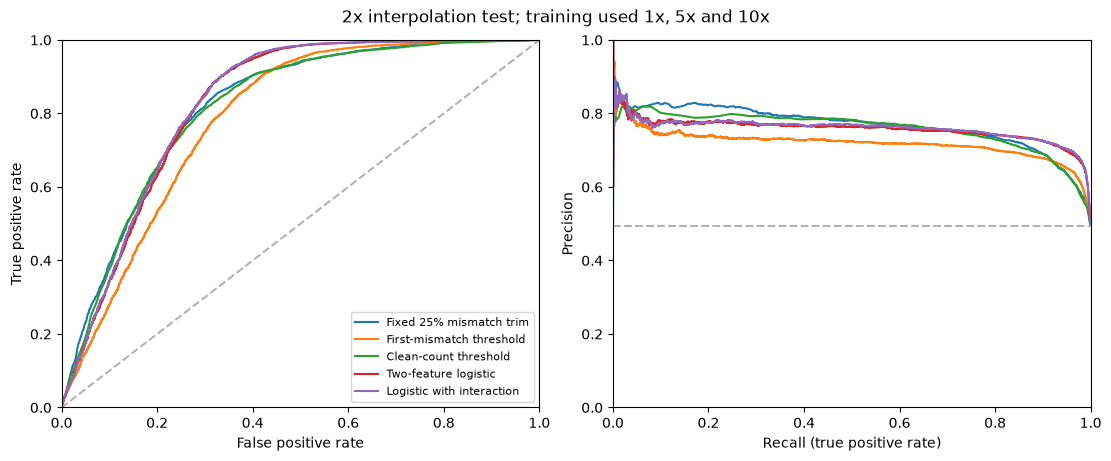

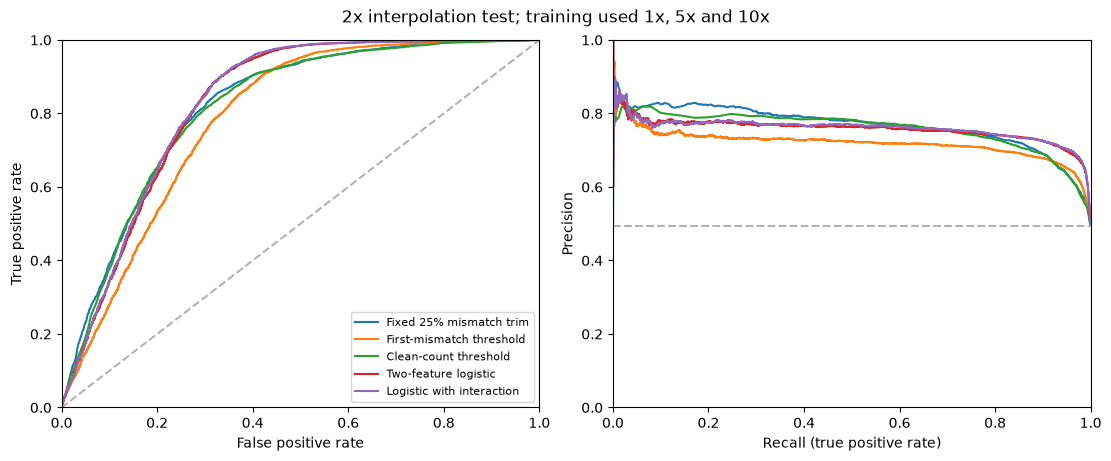

In [20]:
pooled_training_profiles = [
    cumulative_profiles[multiplier] for multiplier in training_multipliers
]
pooled_models = {}
interpolation_rows = []
interpolation_curves = {}
interpolation_profiles = cumulative_profiles[2]
interpolation_estimate = ascertained_estimates[2]
interpolation_true_error = fit_df.loc[
    fit_df["error_multiplier"] == 2, "true_error"
].iloc[0]
for tier in classifier_tiers:
    if tier == "tier_0":
        model = nb_utils.make_doubleton_classifier(tier=tier, threshold=None)
    else:
        model = nb_utils.fit_doubleton_classifier(tier, pooled_training_profiles)
    pooled_models[tier] = model
    scores, retained = nb_utils.classify_doubletons(
        model, interpolation_profiles, interpolation_estimate.mismatches
    )
    metrics = nb_utils.classifier_metrics(
        scores, interpolation_profiles.is_true_doubleton, retained
    )
    fitted = nb_utils.fit_error_rate_with_selected_doubletons(
        interpolation_estimate, retained
    )
    metrics.update(
        {
            "tier": tier,
            "fitted_epsilon": fitted.epsilon,
            "epsilon_relative_error": abs(fitted.epsilon - interpolation_true_error)
            / interpolation_true_error,
        }
    )
    interpolation_rows.append(metrics)
    interpolation_curves[tier] = nb_utils.classifier_curves(
        scores, interpolation_profiles.is_true_doubleton
    )
interpolation_df = pd.DataFrame(interpolation_rows)
ipython_display.display(interpolation_df)
fig = nb_plot.plot_interpolation_at_2x_and_fitted_decision_surfaces(
    classifier_labels=classifier_labels,
    classifier_tiers=classifier_tiers,
    interpolation_curves=interpolation_curves,
    interpolation_profiles=interpolation_profiles,
    figsize=(11, 4.5),
    color="0.7",
    linestyle="--",
    fontsize=8,
)
fig

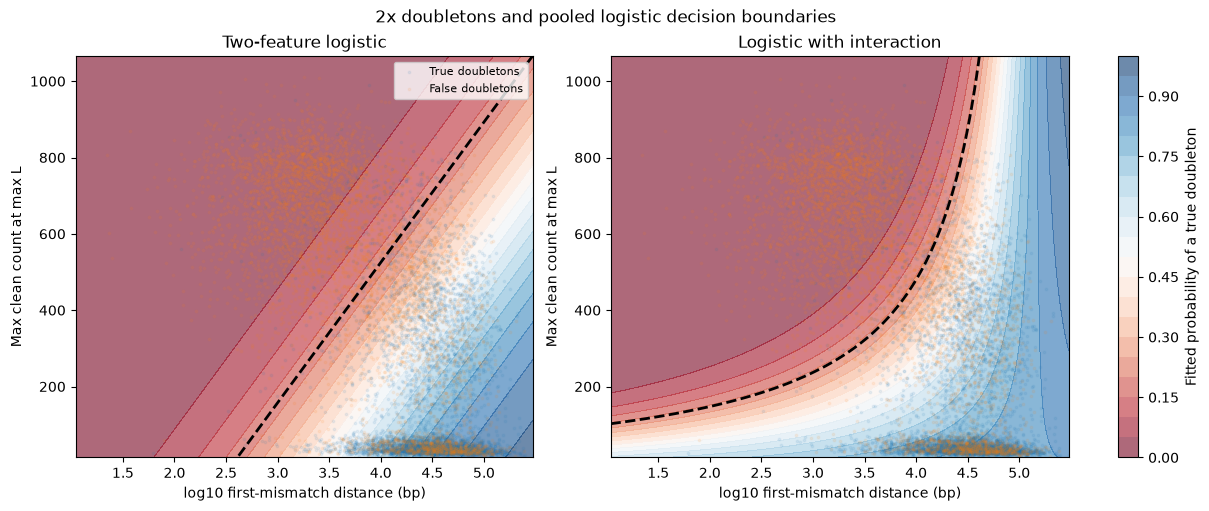

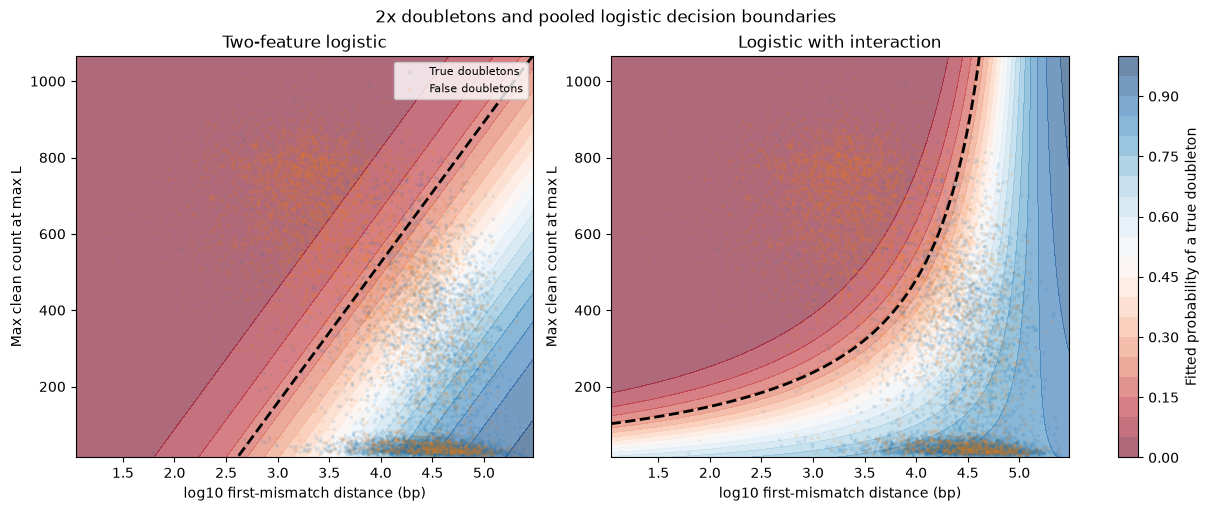

In [21]:
interpolation_features = nb_utils.doubleton_features(interpolation_profiles)
horizontal = np.linspace(
    interpolation_features[:, 0].min(), interpolation_features[:, 0].max(), 120
)
vertical = np.linspace(
    interpolation_features[:, 1].min(), interpolation_features[:, 1].max(), 120
)
grid_x, grid_y = np.meshgrid(horizontal, vertical)
grid_features = np.column_stack((grid_x.ravel(), grid_y.ravel()))
fig = nb_plot.plot_interpolation_at_2x_and_fitted_decision_surfaces_2(
    classifier_labels=classifier_labels,
    grid_features=grid_features,
    grid_x=grid_x,
    grid_y=grid_y,
    interpolation_features=interpolation_features,
    interpolation_profiles=interpolation_profiles,
    pooled_models=pooled_models,
    figsize=(12, 5),
    cmap="RdBu",
    alpha=0.6,
    colors="black",
    linewidths=2,
    s=3,
    alpha_2=0.08,
    fontsize=8,
    label="Fitted probability of a true doubleton",
)
fig

### Selected classifier and downstream error model

Tier 3 is selected: it improves the downstream epsilon fit in all three
held-out error-level comparisons. Its 2x interpolation result is effectively
tied with Tier 2 (relative epsilon error 0.21% versus 0.22%), but the
consistent held-out gain supports the interaction.
The learned threshold targets 95% recall in pooled training data, but recall
varies substantially across held-out error levels. At 10x, the pooled model
retains only 78.7% of true doubletons and still underestimates epsilon by
about 33%. These error levels share one underlying simulation, so this
comparison is not independent validation.

In [22]:
selected_tier = "tier_3"
selected_model = pooled_models[selected_tier]
selected_fit_rows = []
selected_classification_rows = []
for multiplier in error_multipliers:
    estimate = ascertained_estimates[multiplier]
    profiles = cumulative_profiles[multiplier]
    scores, retained = nb_utils.classify_doubletons(
        selected_model, profiles, estimate.mismatches
    )
    fitted = nb_utils.fit_error_rate_with_selected_doubletons(estimate, retained)
    selected_fit_rows.append(
        {
            "error_multiplier": multiplier,
            "epsilon": fitted.epsilon,
            "mu": fitted.mu,
            "sigma_sq": fitted.sigma_sq,
        }
    )
    classification_row = {
        "error_multiplier": multiplier,
        "retained_doubletons": int(retained.sum()),
        "total_doubletons": len(retained),
        "fraction_retained": retained.mean(),
    }
    truth = profiles.is_true_doubleton
    if truth.any() and (~truth).any():
        metrics = nb_utils.classifier_metrics(scores, truth, retained)
        classification_row.update(
            {
                "tpr": metrics["tpr"],
                "fpr": metrics["fpr"],
                "precision": metrics["precision"],
            }
        )
    selected_classification_rows.append(classification_row)
selected_fit_df = fit_df.drop(columns=["epsilon", "mu", "sigma_sq"]).merge(
    pd.DataFrame(selected_fit_rows), on="error_multiplier", validate="one_to_one"
)
selected_classification_df = pd.DataFrame(selected_classification_rows)
ipython_display.display(selected_classification_df)
ipython_display.display(
    selected_fit_df[
        [
            "error_multiplier",
            "true_error",
            "epsilon",
            "true_doubleton_epsilon",
            "mu",
            "sigma_sq",
        ]
    ]
)

/Users/duncan/work/dphil-analysis/src/error_validation.py:94: UserWarning: Some first-mismatch distances are censored at max_L
  warnings.warn("Some first-mismatch distances are censored at max_L")


,error_multiplier,retained_doubletons,total_doubletons,fraction_retained,tpr,fpr,precision
0,0,9913,10000,0.9913,NaN,NaN,NaN
1,1,8101,10000,0.8101,0.975983,0.479029,0.802617
2,2,6754,10000,0.6754,0.956100,0.401028,0.699733
3,5,3753,10000,0.3753,0.904040,0.228075,0.524647
4,10,1348,10000,0.1348,0.829146,0.090716,0.367211


,error_multiplier,true_error,epsilon,true_doubleton_epsilon,mu,sigma_sq
0,0,0.000000,0.000001,0.000003,33.041679,2.283360e+03
1,1,0.000011,0.000013,0.000014,38.311556,4.080013e+03
2,2,0.000022,0.000022,0.000023,43.953087,6.532865e+03
3,5,0.000050,0.000043,0.000047,82.319794,4.218028e+04
4,10,0.000093,0.000059,0.000081,368.127278,1.081794e+06


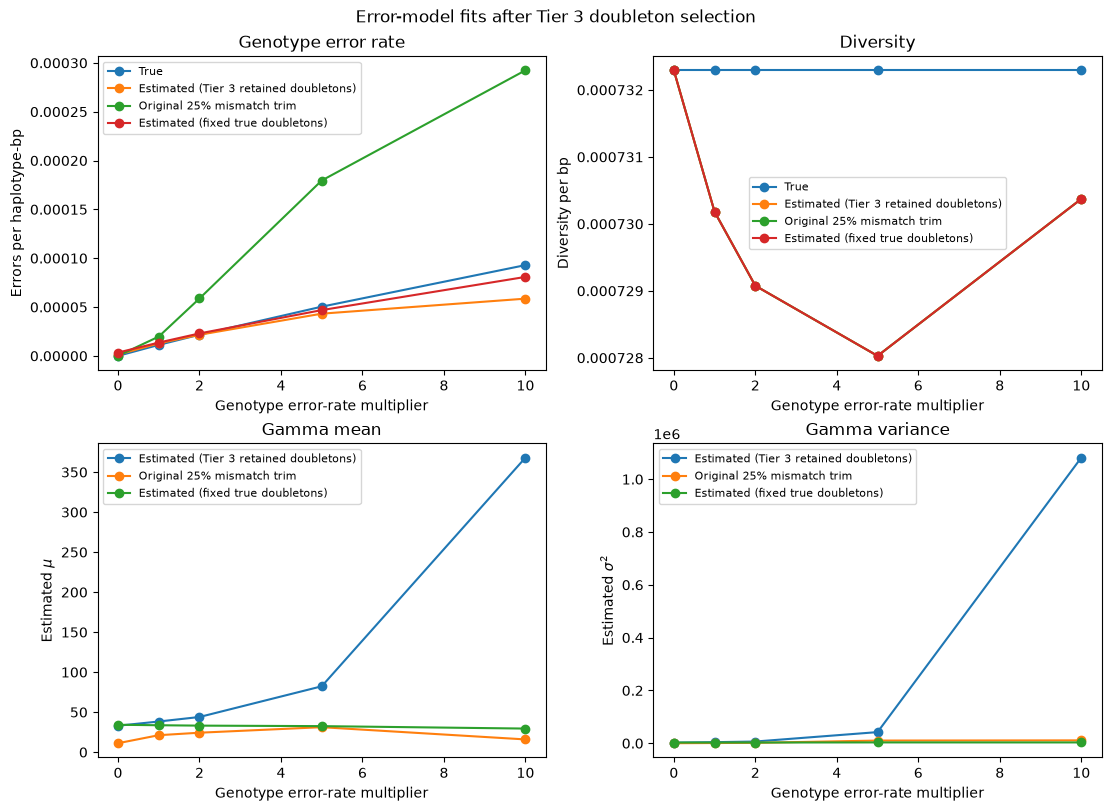

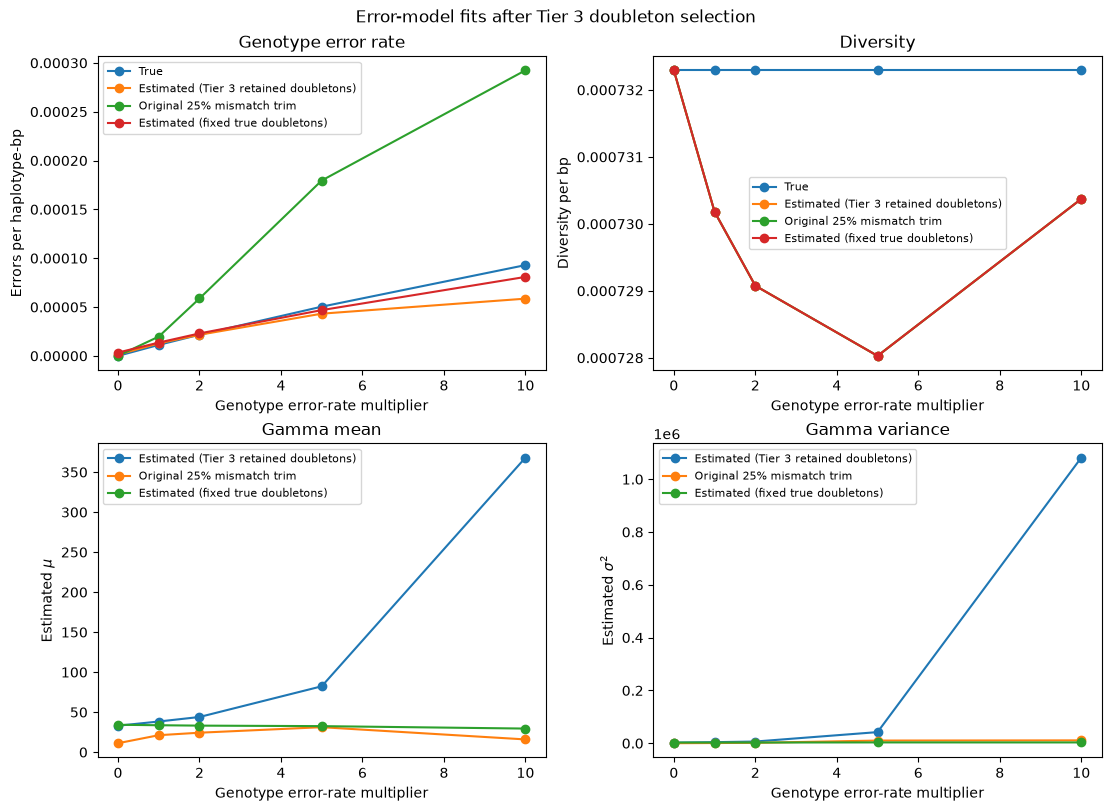

In [23]:
nb_plot.plot_error_estimates(
    selected_fit_df,
    "Estimated (Tier 3 retained doubletons)",
    baseline_frame=fit_df,
    title="Error-model fits after Tier 3 doubleton selection",
    figsize=(11, 8),
)

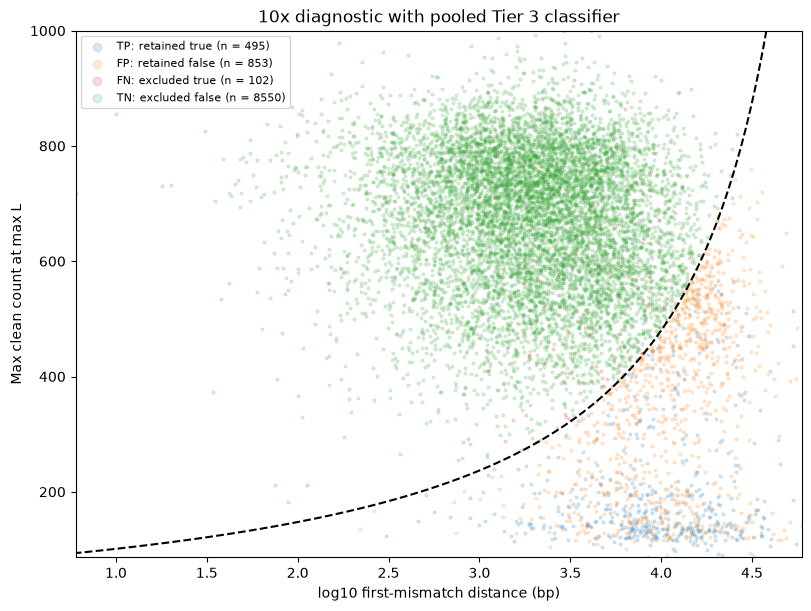

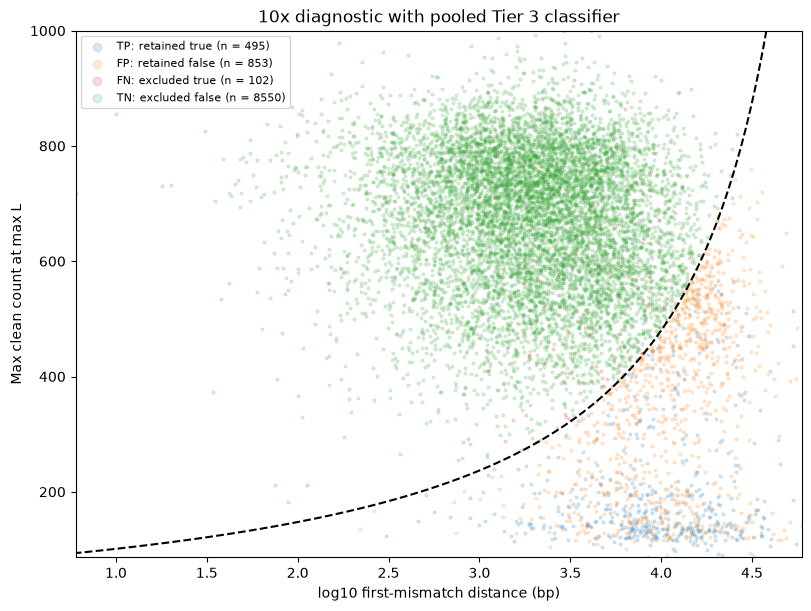

In [24]:
diagnostic_profiles = cumulative_profiles[10]
diagnostic_features = nb_utils.doubleton_features(diagnostic_profiles)
diagnostic_scores, diagnostic_retained = nb_utils.classify_doubletons(
    selected_model, diagnostic_profiles, ascertained_estimates[10].mismatches
)
diagnostic_truth = diagnostic_profiles.is_true_doubleton
outcomes = [
    (diagnostic_retained & diagnostic_truth, "TP: retained true", "tab:blue"),
    (diagnostic_retained & ~diagnostic_truth, "FP: retained false", "tab:orange"),
    (~diagnostic_retained & diagnostic_truth, "FN: excluded true", "tab:red"),
    (~diagnostic_retained & ~diagnostic_truth, "TN: excluded false", "tab:green"),
]
fig = nb_plot.plot_selected_classifier_and_downstream_error_model(
    diagnostic_features=diagnostic_features,
    outcomes=outcomes,
    selected_model=selected_model,
    figsize=(8, 6),
    colors="black",
    s=4,
    alpha=0.16,
    fontsize=8,
)
fig

## Real data

The requested TGP density mask does not itself remove multiallelic rows that
share a position. Combine it with the store's duplicate-position mask so the
estimator receives one biallelic row per genomic position. The local chr17
map copy extends the source map's terminal zero-rate interval to the end of
the Zarr; the map README records this assumption.

In [25]:
tgp_zarr_path = repository_dir / "data/general/zarr_vcfs/tgp/chr17/data.zarr"
tgp_recombination = (
    repository_dir
    / "data/general/HapMapII_GRCh38/genetic_map_Hg38_chr17_for_tgp_zarr.txt"
)
tgp_variant_masks = [
    "variant_all_subset_chr17p_region_filterNton23_site_density_threshold_sites_per_kbp_5_window_size_100000_mask",
    "variant_duplicate_position_mask",
]
tgp_estimate = nb_utils.estimate_error_rate(
    tgp_zarr_path,
    recombination=tgp_recombination,
    config=config,
    variant_mask_name=tgp_variant_masks,
)
tgp_estimate.fit.epsilon

2.3050817285282156e-05

The Johnsson et al. (2021) sex-averaged map uses Sscrofa11.1 coordinates.
The local derived copy extends its terminal zero-rate interval to the final
coordinate in this Zarr; `data/ch4/pig_recombination_map/README.txt` records the
source and the exact adjustment.

In [26]:
pig_window_sizes = np.unique(np.r_[np.geomspace(1000, 1000000, 50), 100000.0])
config2 = nb_utils.make_estimation_config(
    window_sizes=pig_window_sizes,
    num_doubletons=10000,
    random_seed=42,
    exclude_high_mismatch_proportion=0.25,
    L_mismatch_trim=pig_window_sizes[-1],
)
pig_zarr_path = repository_dir / "data/general/zarr_vcfs/pigs/chr18/data.zarr"
pig_recombination = (
    repository_dir
    / "data/ch4/pig_recombination_map/Johnsson_2021_sex_averaged_chr18_for_data_zarr.txt"
)
pig_variant_mask = "variant_allSample_subset_chr18_region_filterDensity_site_density_threshold_sites_per_kbp_10_window_size_1000_mask"
pig_estimate = nb_utils.estimate_error_rate(
    pig_zarr_path,
    recombination=pig_recombination,
    config=config2,
    variant_mask_name=pig_variant_mask,
)
pig_estimate.fit.epsilon

0.00012943902166833777

### Pig chr18 site density and retained quality flags

The current density-threshold mask is applied on its own. Show how much of
chr18 it retains, and which other Zarr quality flags remain among those sites.

,flag,retained_sites_flagged,fraction_of_retained_sites
0,Non-SNP,115207,0.094152
1,Low-quality ancestral allele,169130,0.138220
2,Bad ancestral allele,103613,0.084677
3,Dataset filterDensity mask,332593,0.271808


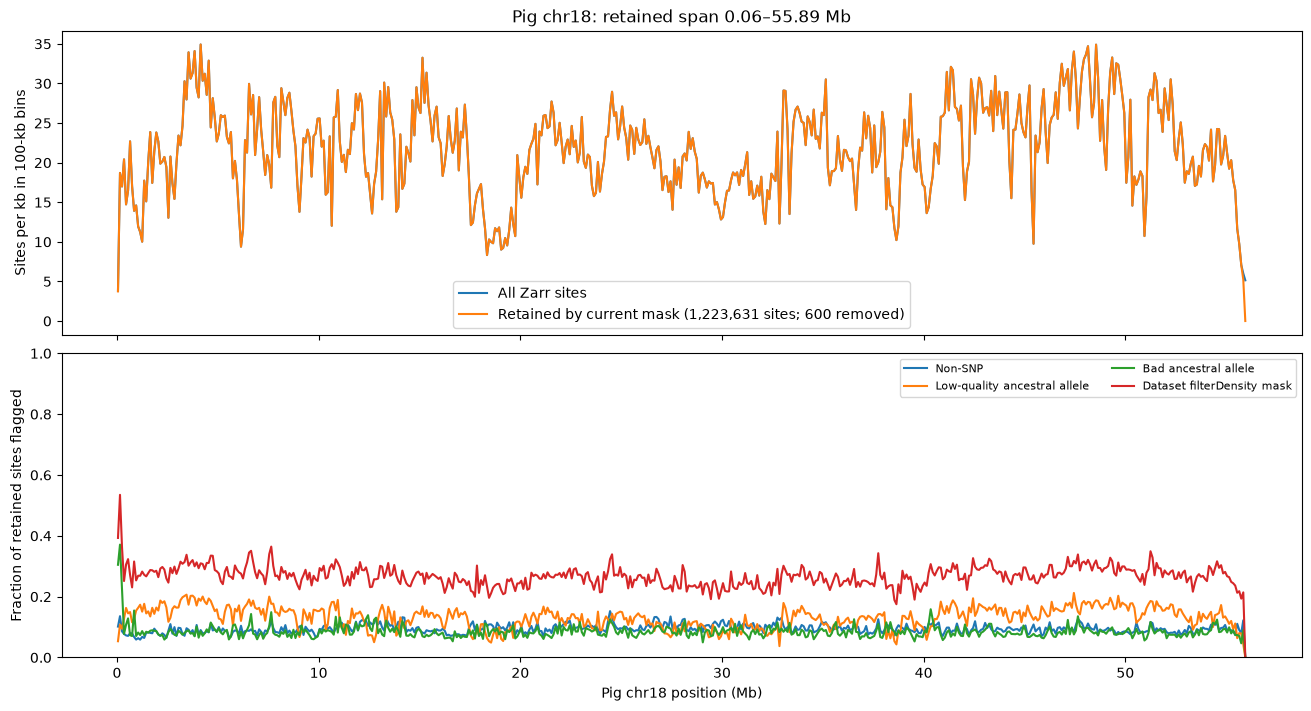

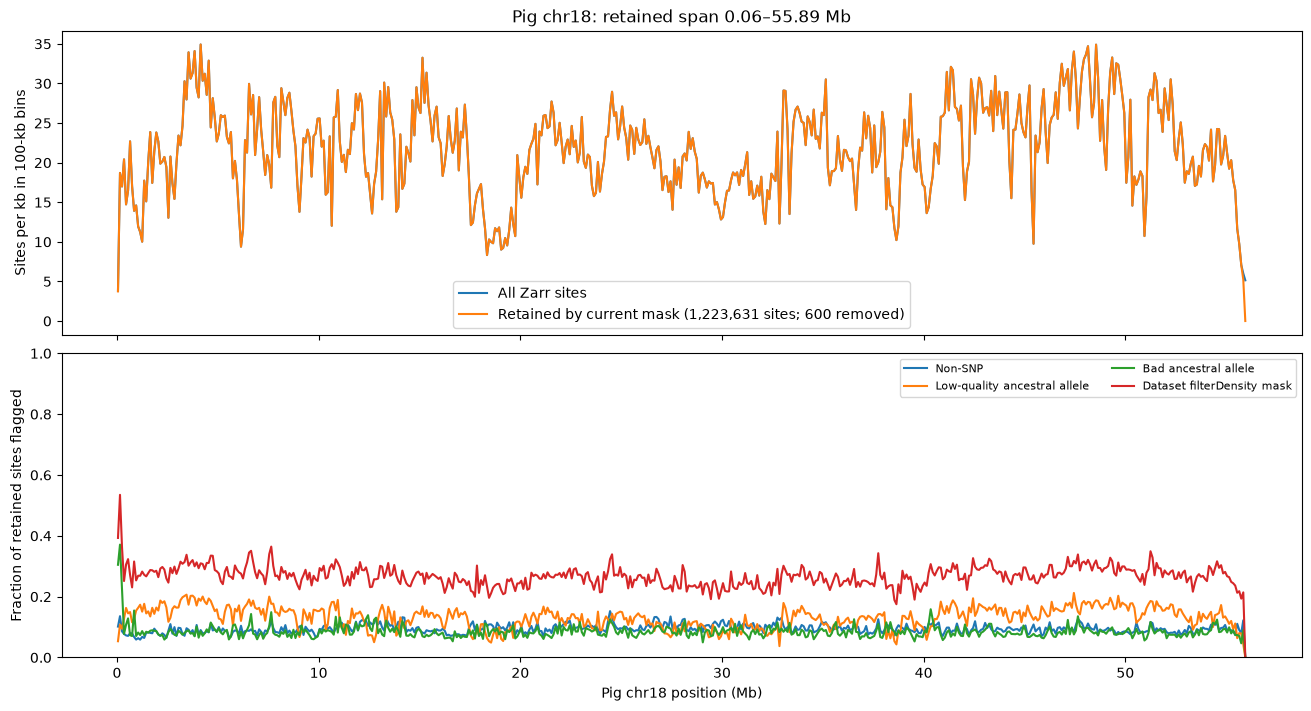

In [27]:
pig_group = zarr.open_group(pig_zarr_path, mode="r")
pig_all_positions = np.asarray(pig_group["variant_position"][:], dtype=float)
pig_excluded = np.asarray(pig_group[pig_variant_mask][:], dtype=bool)
pig_positions = pig_all_positions[~pig_excluded]
pig_bin_width = 100000
pig_bins = np.arange(
    0,
    np.ceil(pig_all_positions[-1] / pig_bin_width) * pig_bin_width + pig_bin_width,
    pig_bin_width,
)
pig_bin_midpoints_mb = (pig_bins[:-1] + pig_bins[1:]) / 2000000.0
all_sites_per_bin, _ = np.histogram(pig_all_positions, bins=pig_bins)
retained_sites_per_bin, _ = np.histogram(pig_positions, bins=pig_bins)
pig_quality_masks = {
    "Non-SNP": "variant_not_snps_mask",
    "Low-quality ancestral allele": "variant_low_quality_ancestral_allele_mask",
    "Bad ancestral allele": "variant_bad_ancestral_mask",
    "Dataset filterDensity mask": "variant_allSample_subset_chr18_region_filterDensity_mask",
}
pig_quality_rows = []
pig_flag_rates = {}
for label, mask_name in pig_quality_masks.items():
    flagged = np.asarray(pig_group[mask_name][:], dtype=bool)[~pig_excluded]
    flagged_counts, _ = np.histogram(pig_positions[flagged], bins=pig_bins)
    pig_flag_rates[label] = np.divide(
        flagged_counts,
        retained_sites_per_bin,
        out=np.zeros_like(flagged_counts, dtype=float),
        where=retained_sites_per_bin > 0,
    )
    pig_quality_rows.append(
        {
            "flag": label,
            "retained_sites_flagged": np.count_nonzero(flagged),
            "fraction_of_retained_sites": flagged.mean(),
        }
    )
pig_quality_df = pd.DataFrame(pig_quality_rows)
ipython_display.display(pig_quality_df)
fig = nb_plot.plot_pig_chr18_site_density_and_retained_quality_flags(
    all_sites_per_bin=all_sites_per_bin,
    pig_bin_midpoints_mb=pig_bin_midpoints_mb,
    pig_excluded=pig_excluded,
    pig_flag_rates=pig_flag_rates,
    pig_positions=pig_positions,
    retained_sites_per_bin=retained_sites_per_bin,
    figsize=(13, 7),
    label="All Zarr sites",
    fontsize=8,
)
fig

In [28]:
pig_mask_comparisons = {"Current density-threshold mask": pig_estimate}
pig_additional_masks = {
    "Plus dataset density-filter flag": [
        pig_variant_mask,
        "variant_allSample_subset_chr18_region_filterDensity_mask",
    ],
    "Plus non-SNP and ancestral flags": [
        pig_variant_mask,
        "variant_not_snps_mask",
        "variant_bad_ancestral_mask",
        "variant_low_quality_ancestral_allele_mask",
    ],
}
for label, masks in pig_additional_masks.items():
    pig_mask_comparisons[label] = nb_utils.estimate_error_rate(
        pig_zarr_path,
        recombination=pig_recombination,
        config=config2,
        variant_mask_name=masks,
    )
pig_mask_rows = []
for label, estimate in pig_mask_comparisons.items():
    pig_mask_rows.append(
        {
            "site_selection": label,
            "num_sites": estimate.diversity.num_sites,
            "eligible_doubletons": estimate.doubletons.num_eligible,
            "epsilon": estimate.fit.epsilon,
            "mu": estimate.fit.mu,
            "sigma_sq": estimate.fit.sigma_sq,
        }
    )
pig_mask_comparison_df = pd.DataFrame(pig_mask_rows)
ipython_display.display(pig_mask_comparison_df)

,site_selection,num_sites,eligible_doubletons,epsilon,mu,sigma_sq
0,Current density-threshold mask,1223631,73732,0.000129,250.272952,245308.132688
1,Plus dataset density-filter flag,891038,56755,0.000073,239.586653,217440.676682
2,Plus non-SNP and ancestral flags,906684,57940,0.000079,249.353308,243820.022254


### Pig fit sensitivity to doubleton trimming

Refit the same sampled doubletons and mismatch windows, ranking exclusions
by the observed count at 100 kb. This isolates trimming from data sampling.

,excluded_proportion,num_doubletons,epsilon,mu,sigma_sq,objective
0,0.00,10000,0.000269,664.120750,1.900018e+06,0.001804
1,0.10,9000,0.000192,463.289080,8.877206e+05,0.003702
2,0.25,7500,0.000129,250.272952,2.453081e+05,0.005772
3,0.50,5000,0.000074,79.892533,2.636762e+04,0.011814
4,0.75,2500,0.000039,14.943603,9.667732e+02,0.034372


Text(0.5, 0.98, 'Pig chr18 fit sensitivity (trim at 100 kb)')

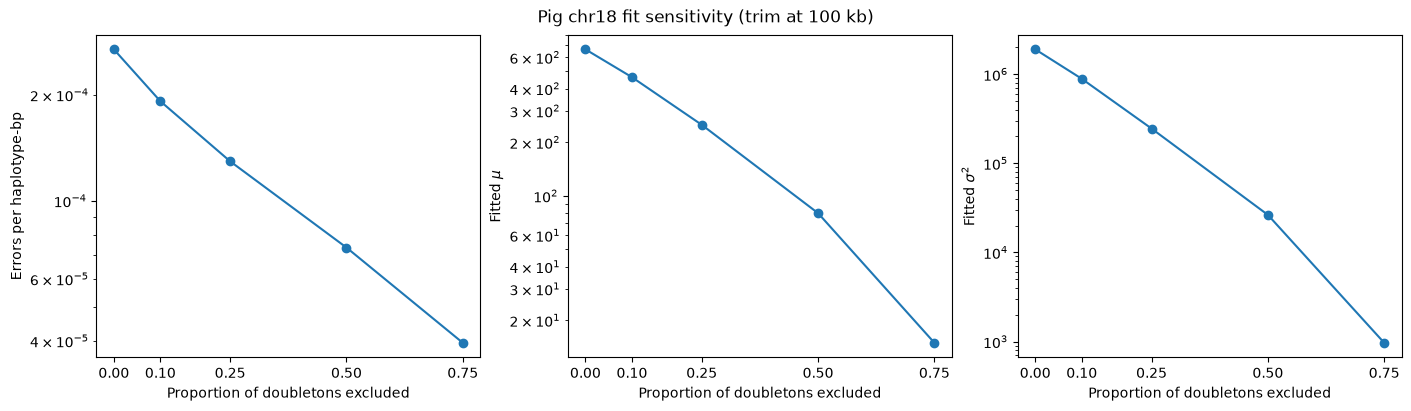

In [29]:
pig_trim_proportions = [0, 0.1, 0.25, 0.5, 0.75]
pig_trim_L = pig_window_sizes[-1]
pig_trim_rows = []
for proportion in pig_trim_proportions:
    trim_config = dataclasses.replace(
        config2, exclude_high_mismatch_proportion=proportion, L_mismatch_trim=pig_trim_L
    )
    fit = nb_utils.fit_error_model(
        pig_estimate.mismatches, pi=pig_estimate.fit.pi, config=trim_config
    )
    pig_trim_rows.append(
        {
            "excluded_proportion": proportion,
            "num_doubletons": fit.num_doubletons,
            "epsilon": fit.epsilon,
            "mu": fit.mu,
            "sigma_sq": fit.sigma_sq,
            "objective": fit.objective,
        }
    )
pig_trim_df = pd.DataFrame(pig_trim_rows)
ipython_display.display(pig_trim_df)
fig = nb_plot.plot_pig_fit_sensitivity_to_doubleton_trimming(
    pig_trim_df=pig_trim_df,
    pig_trim_proportions=pig_trim_proportions,
    figsize=(14, 4),
    marker="o",
)

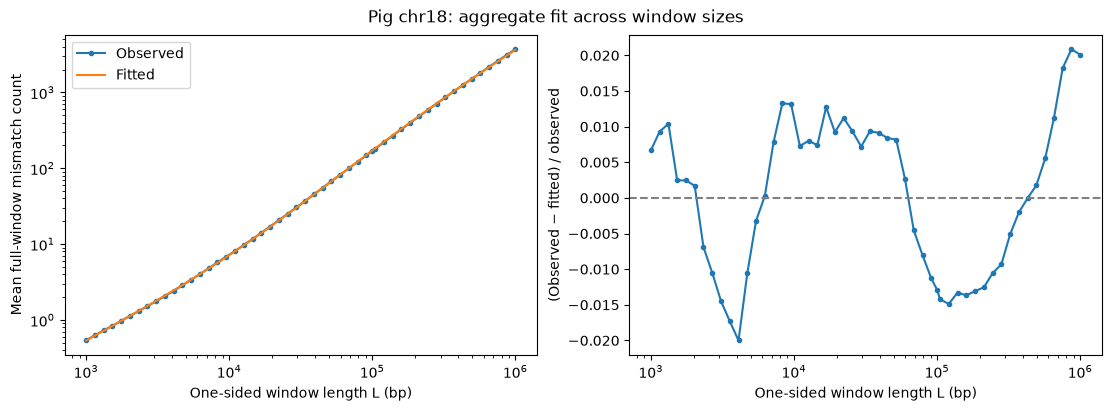

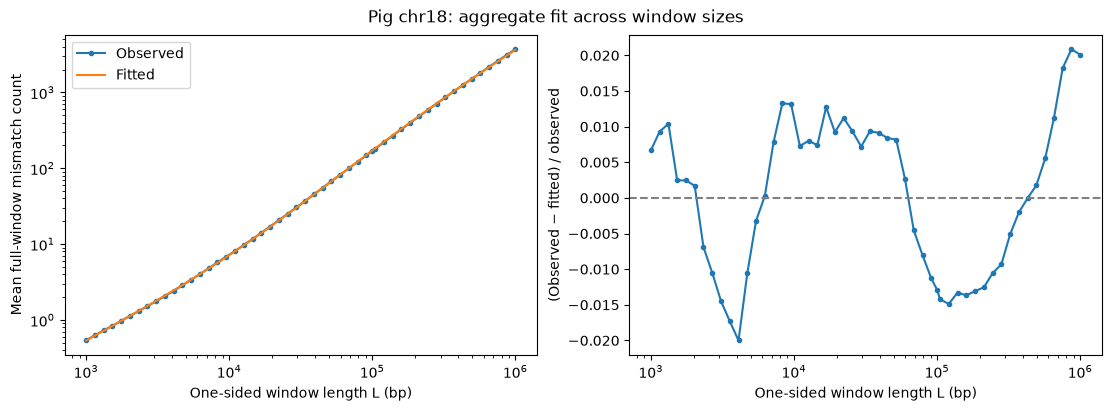

In [30]:
fig = nb_plot.plot_pig_fit_sensitivity_to_doubleton_trimming_2(
    pig_estimate=pig_estimate,
    pig_window_sizes=pig_window_sizes,
    figsize=(11, 4),
    marker=".",
    label="Observed",
    label_2="Fitted",
    color="0.5",
    linestyle="--",
)
fig

### Pig doubleton mismatches and local site density

,flag,flagged_doubletons,median_mismatches_flagged,median_mismatches_unflagged
0,Non-SNP,1023,5366.0,5129.0
1,Low-quality ancestral allele,790,5799.0,5080.0
2,Bad ancestral allele,652,5733.0,5097.5
3,Dataset filterDensity mask,2313,5613.0,5017.0


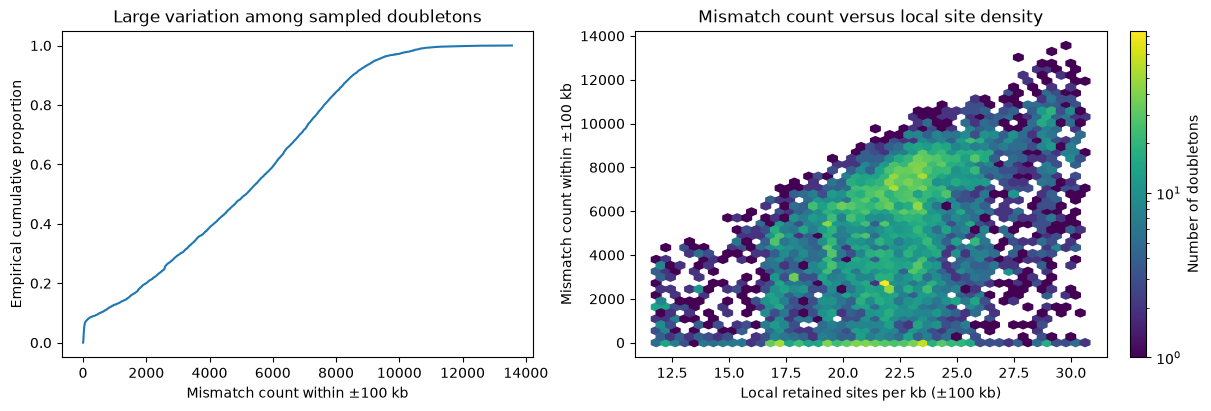

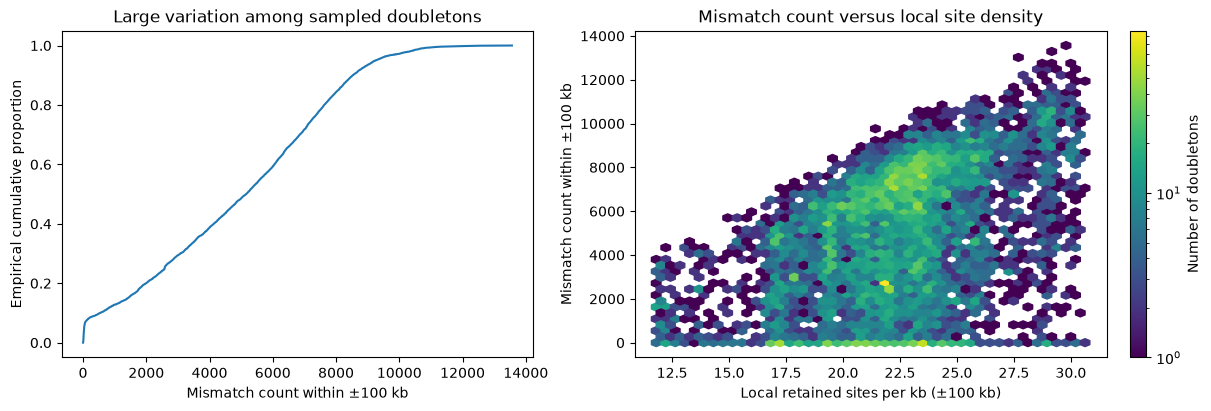

In [31]:
pig_trim_index = np.flatnonzero(pig_window_sizes == pig_trim_L)[0]
pig_trim_counts = pig_estimate.mismatches.counts[pig_trim_index]
pig_focal_positions = pig_estimate.doubletons.positions
pig_local_left = np.searchsorted(
    pig_positions, pig_focal_positions - pig_trim_L, side="left"
)
pig_local_right = np.searchsorted(
    pig_positions, pig_focal_positions + pig_trim_L, side="right"
)
pig_local_sites_per_kb = (pig_local_right - pig_local_left) / (2 * pig_trim_L / 1000)
pig_raw_focal_indices = np.flatnonzero(~pig_excluded)[
    pig_estimate.doubletons.site_indices
]
pig_focal_quality_rows = []
for label, mask_name in pig_quality_masks.items():
    flagged = np.asarray(pig_group[mask_name][:], dtype=bool)[pig_raw_focal_indices]
    pig_focal_quality_rows.append(
        {
            "flag": label,
            "flagged_doubletons": np.count_nonzero(flagged),
            "median_mismatches_flagged": np.median(pig_trim_counts[flagged]),
            "median_mismatches_unflagged": np.median(pig_trim_counts[~flagged]),
        }
    )
pig_focal_quality_df = pd.DataFrame(pig_focal_quality_rows)
ipython_display.display(pig_focal_quality_df)
fig = nb_plot.plot_pig_doubleton_mismatches_and_local_site_density(
    pig_local_sites_per_kb=pig_local_sites_per_kb,
    pig_trim_counts=pig_trim_counts,
    figsize=(12, 4),
    gridsize=45,
    bins="log",
    label="Number of doubletons",
)
fig

The current mask retains nearly all sites across 0.06–55.89 Mb. Several
quality flags remain among the retained rows, and flagged focal doubletons
tend to have higher mismatch counts at 100 kb. Local site density also varies
markedly, but the scatter shows a broad range of mismatch counts at any given
density. The aggregate fitted curve follows the observed mean closely while
the fitted parameters change by orders of magnitude under trimming; the
residual objective also rises sharply with the most aggressive exclusions.
Removing the additional flagged site sets reduces the fitted variance only
modestly.
Those mask comparisons also resample eligible doubletons and recalculate
diversity, so they are sensitivity checks rather than isolated flag effects.
These checks identify heterogeneity and fit sensitivity; they do not by
themselves distinguish technical error from population structure or a model
mismatch.

## Using doubleton classifiers on real data

Doubletons are sampled from each dataset's masked site list. Verify that the
selected-to-raw Zarr mapping used for one-sided features is the same mapping
used for the original mismatch summary. Then reuse each estimate's sampled
doubletons, global diversity and recombination rates for every classifier.

In [32]:
real_datasets = {
    "TGP chr17": (tgp_estimate, tgp_zarr_path, tgp_variant_masks),
    "Pig chr18": (pig_estimate, pig_zarr_path, [pig_variant_mask]),
}
real_profiles = {}
real_selections = {}
real_rows = []
for dataset, (estimate, zarr_path, mask_names) in real_datasets.items():
    group = zarr.open_group(zarr_path, mode="r")
    excluded_variants = np.zeros(group["variant_position"].shape[0], dtype=bool)
    for mask_name in mask_names:
        excluded_variants |= np.asarray(group[mask_name][:], dtype=bool)
    expected_raw_indices = np.flatnonzero(~excluded_variants)
    assert np.array_equal(estimate.included_variant_indices, expected_raw_indices)
    raw_positions = np.asarray(group["variant_position"][:])
    assert np.array_equal(
        estimate.included_positions, raw_positions[expected_raw_indices]
    )
    assert np.array_equal(
        estimate.doubletons.positions,
        estimate.included_positions[estimate.doubletons.site_indices],
    )
    max_L = estimate.config.window_sizes[-1]
    profiles = nb_utils.cumulative_mismatch_profiles(
        estimate, distances=np.array([max_L])
    )
    real_profiles[dataset] = profiles
    assert profiles.is_true_doubleton is None
    assert profiles.max_clean_count.shape == estimate.doubletons.positions.shape
    assert (
        profiles.max_first_mismatch_distance.shape
        == estimate.doubletons.positions.shape
    )
    assert np.array_equal(
        profiles.max_left_count + profiles.max_right_count,
        estimate.mismatches.counts[-1],
    )
    real_selections[dataset] = {}
    for tier in classifier_tiers:
        model = pooled_models[tier]
        scores, retained = nb_utils.classify_doubletons(
            model,
            profiles,
            estimate.mismatches,
            baseline_excluded=estimate.config.exclude_high_mismatch_proportion,
        )
        assert len(retained) == len(estimate.doubletons.positions)
        real_selections[dataset][tier] = retained
        if tier == "tier_0":
            fitted = estimate.fit
            assert fitted.num_doubletons == retained.sum()
        else:
            fitted = nb_utils.fit_error_rate_with_selected_doubletons(
                estimate, retained
            )
        real_rows.append(
            {
                "dataset": dataset,
                "tier": tier,
                "sampled_doubletons": len(retained),
                "retained_doubletons": int(retained.sum()),
                "excluded_doubletons": int((~retained).sum()),
                "epsilon": fitted.epsilon,
                "diversity": estimate.diversity.global_pi_per_bp,
                "mu": fitted.mu,
                "sigma_sq": fitted.sigma_sq,
                "fit_success": fitted.success,
                "first_mismatch_censored": int(
                    profiles.max_first_mismatch_censored.sum()
                ),
            }
        )
real_classifier_df = pd.DataFrame(real_rows)
ipython_display.display(real_classifier_df)

/Users/duncan/work/dphil-analysis/src/error_validation.py:94: UserWarning: Some first-mismatch distances are censored at max_L
  warnings.warn("Some first-mismatch distances are censored at max_L")


,dataset,tier,sampled_doubletons,retained_doubletons,excluded_doubletons,epsilon,diversity,mu,sigma_sq,fit_success,first_mismatch_censored
0,TGP chr17,tier_0,10000,7500,2500,0.000023,0.000908,22.698957,1611.836007,True,1008
1,TGP chr17,tier_1,10000,8659,1341,0.000010,0.000908,127.995262,97323.285773,True,1008
2,TGP chr17,tier_1b,10000,7794,2206,0.000030,0.000908,28.609598,3467.793213,True,1008
3,TGP chr17,tier_2,10000,7928,2072,0.000009,0.000908,48.334006,9731.091850,True,1008
4,TGP chr17,tier_3,10000,8133,1867,0.000010,0.000908,53.998187,11149.081351,True,1008
5,Pig chr18,tier_0,10000,7500,2500,0.000129,0.003514,250.272952,245308.132688,True,10
6,Pig chr18,tier_1,10000,8178,1822,0.000016,0.003514,576.660388,994731.405063,True,10
7,Pig chr18,tier_1b,10000,2717,7283,0.000032,0.003514,30.904796,4390.629837,True,10
8,Pig chr18,tier_2,10000,2907,7093,0.000021,0.003514,31.534859,3253.405213,True,10
9,Pig chr18,tier_3,10000,3806,6194,0.000019,0.003514,51.457429,4849.643868,True,10


### Exclusions by predictor

Tier 1 uses mismatch-free distance; Tier 1b uses clean-side count. The
overlap partitions describe their individual rules, while Tiers 2 and 3
combine the predictors and have no unique per-predictor attribution.

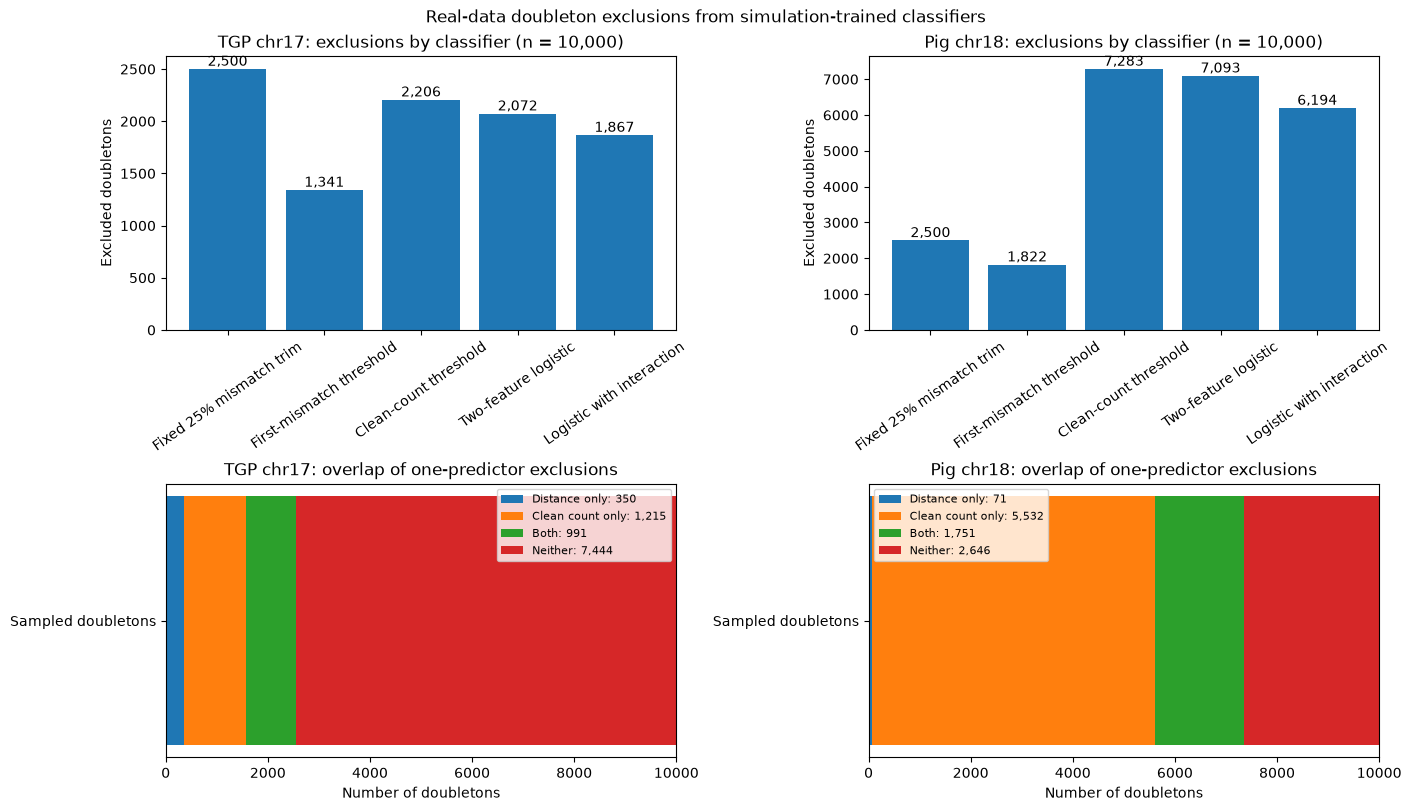

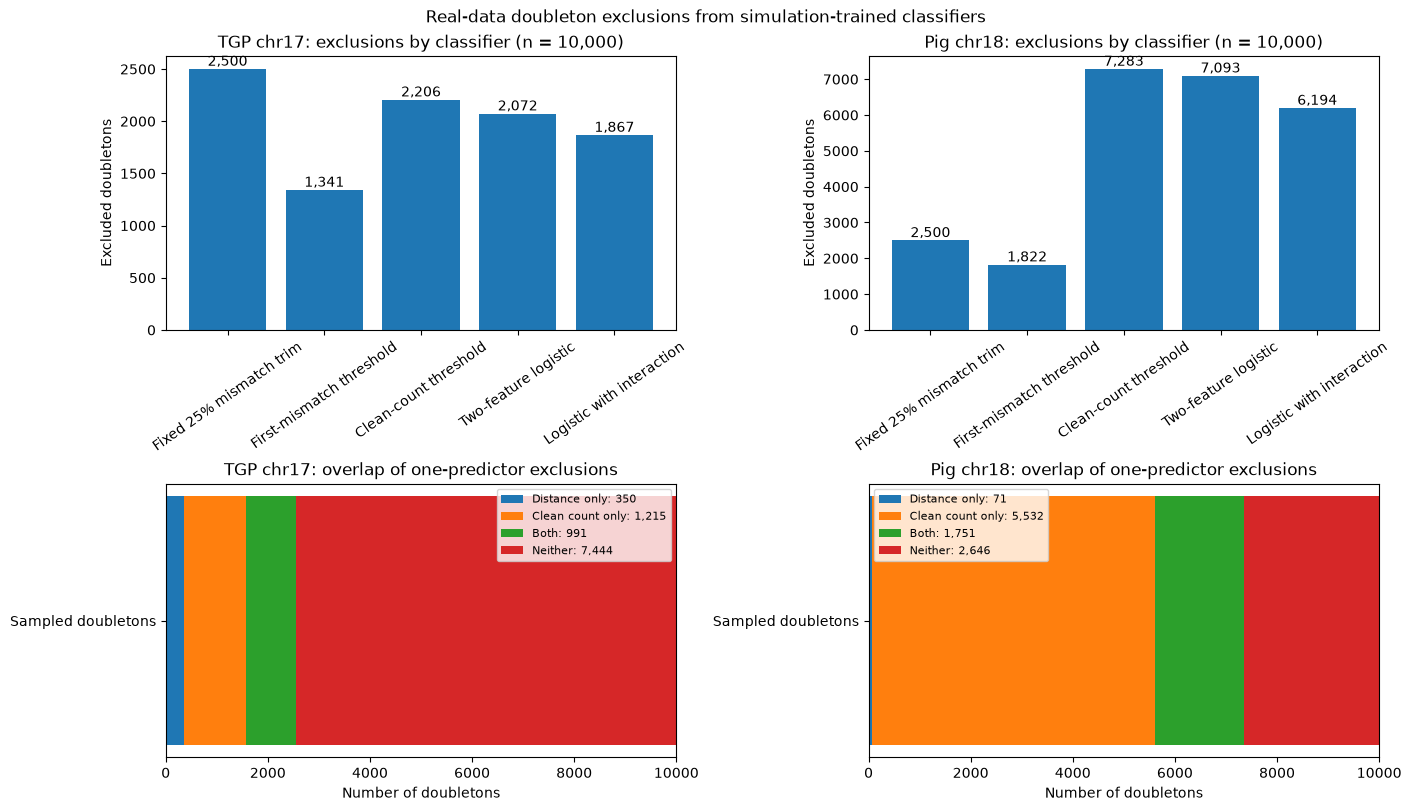

In [33]:
fig = nb_plot.plot_exclusions_by_predictor(
    classifier_labels=classifier_labels,
    classifier_tiers=classifier_tiers,
    real_classifier_df=real_classifier_df,
    real_datasets=real_datasets,
    real_selections=real_selections,
    figsize=(14, 8),
    fontsize=8,
)
fig

/Users/duncan/work/dphil-analysis/src/error_validation.py:94: UserWarning: Some first-mismatch distances are censored at max_L
  warnings.warn("Some first-mismatch distances are censored at max_L")


Text(0.5, 0.98, 'Classifier predictor distributions in training and real data')

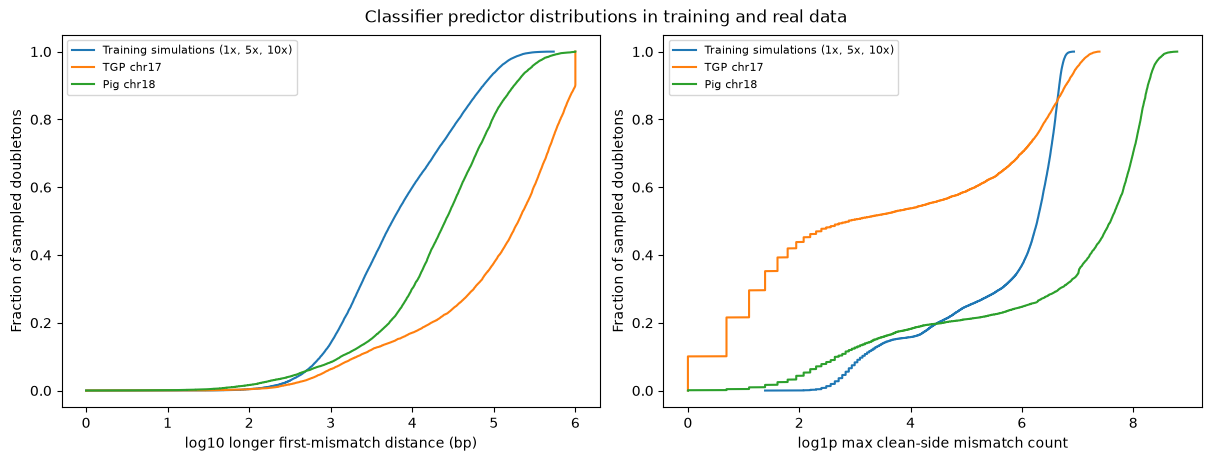

In [34]:
feature_sets = {
    "Training simulations (1x, 5x, 10x)": np.concatenate(
        [nb_utils.doubleton_features(profiles) for profiles in pooled_training_profiles]
    )
}
for dataset, profiles in real_profiles.items():
    feature_sets[dataset] = nb_utils.doubleton_features(profiles)
fig = nb_plot.plot_exclusions_by_predictor_2(
    feature_sets=feature_sets, figsize=(12, 4.5), fontsize=8
)

### Error-model estimates by tier

Diversity uses all variants retained by the dataset's site masks, so it is
the same for every doubleton classifier. Tier 1b remains in the results
table above as an independent predictor check; these figures show the four
numbered tiers requested for comparison.
The real-data predictor distributions differ from those in the training
simulations. In particular, the pig clean-count rule excludes many more
doubletons than the distance-only rule. The large changes in pig epsilon and
sigma-squared across tiers are fit sensitivity, not validation of the
simulation-trained classifier on that dataset. With the current masks, Tier
3 retains 8,369 TGP and 4,454 pig doubletons; the corresponding epsilon fits
are approximately 1.08e-5 and 1.71e-5 errors per haplotype-bp. TGP has
1,008 first-mismatch distances censored at 1 Mb, compared with 10 in pig.
These shifts may reflect genotype quality, population structure, or model
transfer; they do not identify the real error rate without external truth.

None

None

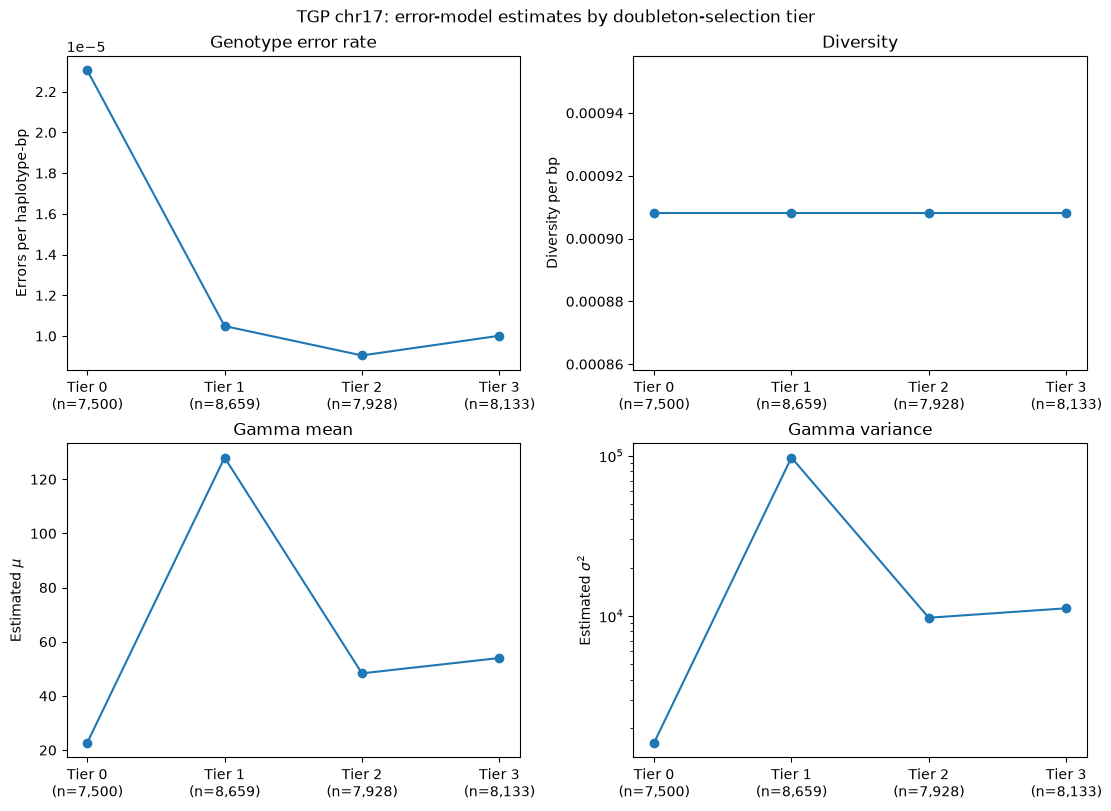

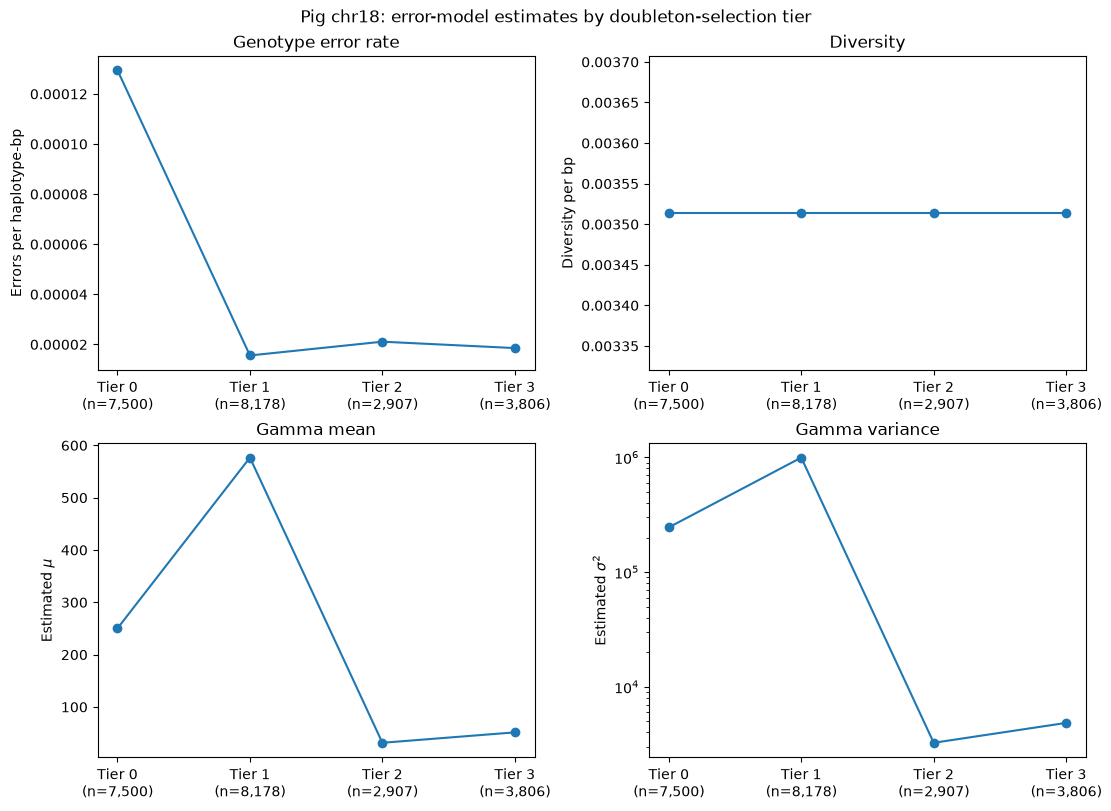

In [35]:
for dataset in real_datasets:
    ipython_display.display(
        nb_plot.plot_real_classifier_estimates(
            real_classifier_df, dataset, figsize=(11, 8)
        )
    )

### Real Tier 3 epsilon against simulation estimates

The horizontal lines show the fitted values on the real datasets. The
simulated multiplier is a reference axis, not an inferred real-data error
multiplier.

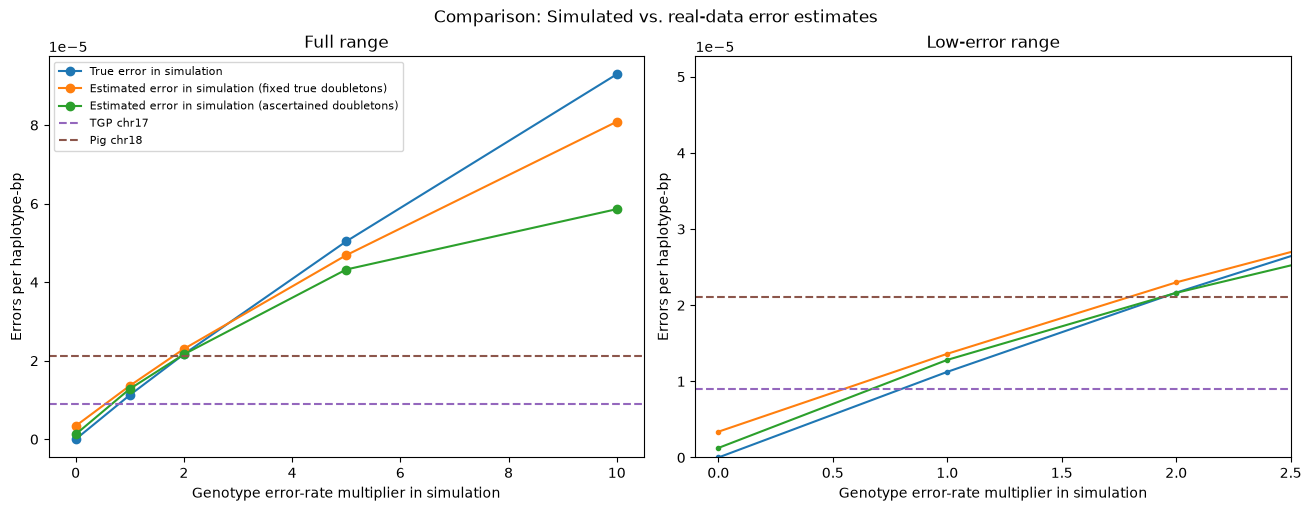

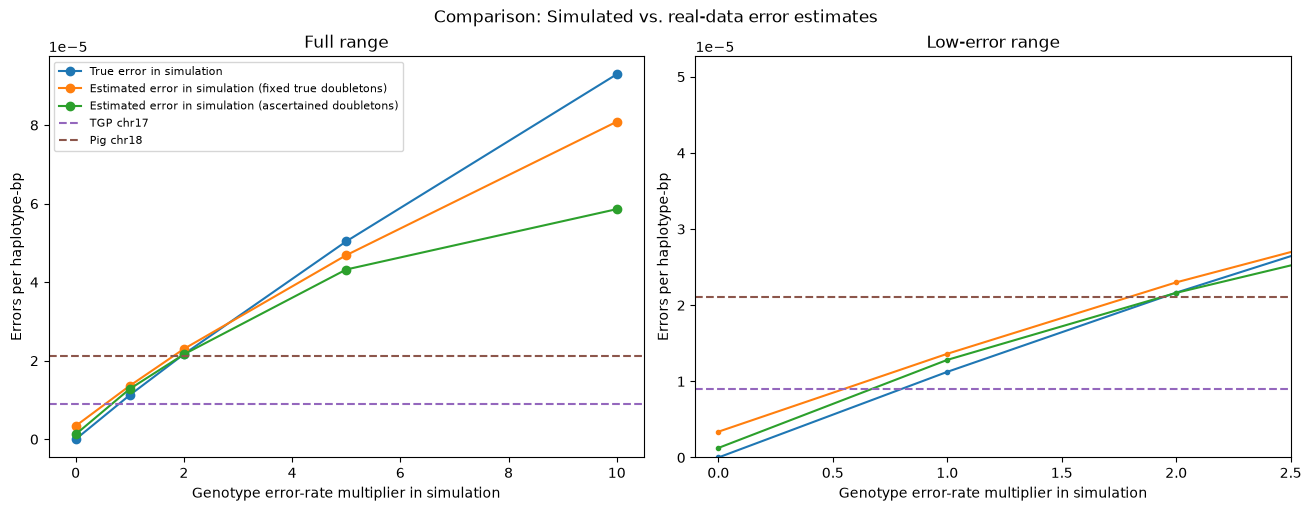

In [40]:
fig = nb_plot.plot_real_tier_3_epsilon_against_simulation_estimates(
    fit_df=fit_df,
    real_classifier_df=real_classifier_df,
    selected_fit_df=selected_fit_df,
    figsize=(13, 5),
    marker="o",
    markersize=3,
    linestyle="--",
    fontsize=8,
)
fig